In [2]:
from pathlib import Path
import importlib.util
import os
import sys

PROJECT_DIR = Path.cwd()

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("PYTHON VERSION:", sys.version)

print("\n--- REQUIRED PACKAGES ---")

packages = [
    "ee",
    "geemap",
    "rasterio",
    "torch",
    "numpy",
    "pandas",
    "pyproj",
    "streamlit"
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:15} : {'AVAILABLE' if available else 'NOT INSTALLED'}")

print("\n--- PROJECT FILES ---")

for item in [
    "app.py",
    "src/model.py",
    "src/inference.py",
    "src/location.py",
    "src/analysis.py",
    "outputs/best_unet_v5.pt",
    "monthly_inputs"
]:
    path = PROJECT_DIR / item
    print(f"{item:35} : {'EXISTS' if path.exists() else 'MISSING'}")

print("\n--- EARTH ENGINE ENVIRONMENT ---")

print(
    "EE_PROJECT environment variable:",
    os.environ.get("EE_PROJECT", "NOT SET")
)

PROJECT DIRECTORY: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc
PYTHON VERSION: 3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]

--- REQUIRED PACKAGES ---
ee              : NOT INSTALLED
geemap          : NOT INSTALLED
rasterio        : NOT INSTALLED
torch           : AVAILABLE
numpy           : AVAILABLE
pandas          : AVAILABLE
pyproj          : NOT INSTALLED
streamlit       : NOT INSTALLED

--- PROJECT FILES ---
app.py                              : EXISTS
src/model.py                        : EXISTS
src/inference.py                    : EXISTS
src/location.py                     : EXISTS
src/analysis.py                     : EXISTS
outputs/best_unet_v5.pt             : EXISTS
monthly_inputs                      : EXISTS

--- EARTH ENGINE ENVIRONMENT ---
EE_PROJECT environment variable: NOT SET


In [3]:
import sys
import subprocess
import shutil

print("=== JUPYTER KERNEL ===")
print("Python executable:", sys.executable)
print("Python version:", sys.version)

print("\n=== SYSTEM PYTHON ===")
print("Python path:", shutil.which("python"))
print("Python3 path:", shutil.which("python3"))

print("\n=== SYSTEM PYTHON PACKAGES ===")

result = subprocess.run(
    [
        "/usr/bin/python",
        "-c",
        """
import sys, importlib.util
print("Executable:", sys.executable)

packages = [
    "ee", "rasterio", "torch", "numpy",
    "pandas", "pyproj", "streamlit"
]

for p in packages:
    print(p, ":", importlib.util.find_spec(p) is not None)
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

=== JUPYTER KERNEL ===
Python executable: /usr/bin/python
Python version: 3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]

=== SYSTEM PYTHON ===
Python path: /usr/bin/python
Python3 path: /usr/bin/python3

=== SYSTEM PYTHON PACKAGES ===
Executable: /usr/bin/python
ee : False
rasterio : False
torch : True
numpy : True
pandas : True
pyproj : False
streamlit : False




In [4]:
import sys
import subprocess
import shutil
import os
from pathlib import Path

print("=== PYTHON AND PIP ===")
for command in ["python", "python3", "pip", "pip3", "streamlit"]:
    print(f"{command}: {shutil.which(command)}")

print("\n=== PIP INFORMATION ===")
subprocess.run(
    [sys.executable, "-m", "pip", "--version"],
    capture_output=False
)

print("\n=== COMMON ENVIRONMENT LOCATIONS ===")
for path in [
    Path.home() / ".local/bin/streamlit",
    Path.home() / ".local/lib/python3.12/site-packages",
    Path("/opt/conda/bin/python"),
    Path("/opt/venv/bin/python"),
    Path("/usr/local/bin/streamlit"),
    Path("/usr/local/bin/python"),
]:
    print(f"{path}: {path.exists()}")

print("\n=== RELEVANT ENVIRONMENT VARIABLES ===")
for key in ["VIRTUAL_ENV", "CONDA_PREFIX", "PATH", "PYTHONPATH"]:
    print(f"{key}: {os.environ.get(key)}")

print("\n=== RUNNING STREAMLIT PROCESSES ===")
subprocess.run(
    ["ps", "-ef"],
    capture_output=True,
    text=True
).stdout

=== PYTHON AND PIP ===
python: /usr/bin/python
python3: /usr/bin/python3
pip: /usr/local/bin/pip
pip3: /usr/local/bin/pip3
streamlit: None

=== PIP INFORMATION ===
pip 25.3 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)

=== COMMON ENVIRONMENT LOCATIONS ===
/home/jovyan/.local/bin/streamlit: False
/home/jovyan/.local/lib/python3.12/site-packages: True
/opt/conda/bin/python: False
/opt/venv/bin/python: False
/usr/local/bin/streamlit: False
/usr/local/bin/python: False

=== RELEVANT ENVIRONMENT VARIABLES ===
VIRTUAL_ENV: None
CONDA_PREFIX: None
PATH: /usr/local/lib/python3.12/dist-packages/torch_tensorrt/bin:/usr/local/nvidia/bin:/usr/local/cuda/bin:/usr/local/mpi/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin:/usr/local/ucx/bin:/opt/amazon/efa/bin:/opt/tensorrt/bin:/home/jovyan/.local/bin
PYTHONPATH: /home/jovyan

=== RUNNING STREAMLIT PROCESSES ===


'UID          PID    PPID  C STIME TTY          TIME CMD\njovyan         1       0 10 14:30 ?        00:00:06 /usr/bin/python /usr/local/bin/jupyterhub-singleuser\njovyan       264       1  1 14:31 ?        00:00:00 /usr/bin/python -m ipykernel_launcher -f /home/jovyan/.local/share/jupyter/runtime/kernel-803cf4b7-164d-4867-abae-70bc935528cc.json\njovyan       284     264  0 14:31 ?        00:00:00 ps -ef\n'

In [5]:
import sys
import subprocess
import shutil
import site
from pathlib import Path

print("=== PYTHON ===")
print(sys.executable)
print("User site:", site.getusersitepackages())
print("System sites:", site.getsitepackages())

print("\n=== PIP ===")
subprocess.run([sys.executable, "-m", "pip", "--version"])

print("\n=== EXECUTABLES ===")
for name in ["streamlit", "cloudflared", "jupyter", "pip"]:
    print(name, ":", shutil.which(name))

print("\n=== PACKAGE DIRECTORIES ===")
paths = [
    Path.home() / ".local/lib/python3.12/site-packages",
    Path("/usr/local/lib/python3.12/site-packages"),
    Path("/usr/lib/python3/dist-packages"),
]

for path in paths:
    print(f"\n{path} | exists: {path.exists()}")
    if path.exists():
        for pattern in ["streamlit*", "rasterio*", "pyproj*", "earthengine_api*", "ee*"]:
            matches = list(path.glob(pattern))
            if matches:
                print(pattern, ":", [p.name for p in matches[:5]])

print("\n=== PROJECT EXECUTABLE ===")
project = Path("/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc")
for path in [
    project / "bin/cloudflared",
    project / ".venv/bin/python",
    project / "venv/bin/python",
]:
    print(path, "| exists:", path.exists())

=== PYTHON ===
/usr/bin/python
User site: /home/jovyan/.local/lib/python3.12/site-packages
System sites: ['/usr/local/lib/python3.12/dist-packages', '/usr/lib/python3/dist-packages', '/usr/lib/python3.12/dist-packages']

=== PIP ===
pip 25.3 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)

=== EXECUTABLES ===
streamlit : None
cloudflared : None
jupyter : /usr/local/bin/jupyter
pip : /usr/local/bin/pip

=== PACKAGE DIRECTORIES ===

/home/jovyan/.local/lib/python3.12/site-packages | exists: True

/usr/local/lib/python3.12/site-packages | exists: False

/usr/lib/python3/dist-packages | exists: True

=== PROJECT EXECUTABLE ===
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/bin/cloudflared | exists: True
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python | exists: True
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/venv/bin/python | exists: False


In [6]:
import subprocess
import sys
from pathlib import Path

print("=== INSTALLED PYTHON PACKAGES ===")
subprocess.run([sys.executable, "-m", "pip", "list"])

print("\n=== PROJECT REQUIREMENTS ===")
requirements = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/requirements.txt"
)

if requirements.exists():
    print(requirements.read_text())
else:
    print("requirements.txt not found")

print("\n=== USER SITE PACKAGES ===")
user_site = Path.home() / ".local/lib/python3.12/site-packages"

if user_site.exists():
    for item in sorted(user_site.iterdir()):
        print(item.name)

=== INSTALLED PYTHON PACKAGES ===
Package                                 Version           Build
--------------------------------------- ----------------- --------
absl-py                                 2.3.1
accelerate                              1.12.0
aiohappyeyeballs                        2.6.1
aiohttp                                 3.13.2
aiosignal                               1.4.0
aiosqlite                               0.22.1
alembic                                 1.17.2
annotated-doc                           0.0.4
annotated-types                         0.7.0
anthropic                               0.71.0
anyio                                   4.11.0
apache-tvm-ffi                          0.1.7
apex                                    0.1
argon2-cffi                             25.1.0
argon2-cffi-bindings                    25.1.0
arrow                                   1.4.0
astor                                   0.8.1
asttokens                               3.0.0
a

In [7]:
from pathlib import Path

PROJECT = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc"
)

print("=== DEPENDENCY FILES ===")

for pattern in [
    "**/requirements.txt",
    "**/pyproject.toml",
    "**/environment.yml",
]:
    matches = list(PROJECT.glob(pattern))
    for path in matches:
        print(path.relative_to(PROJECT))

print("\n=== DELIVERABLES DIRECTORY ===")

deliverables = PROJECT / "deliverables_v5"

if deliverables.exists():
    for item in sorted(deliverables.iterdir()):
        print(item.name)
else:
    print("deliverables_v5 not found")

=== DEPENDENCY FILES ===
deliverables_v5/requirements.txt

=== DELIVERABLES DIRECTORY ===
README.md
environment_versions.csv
local_location_analysis
requirements.txt


In [8]:
from pathlib import Path

PROJECT = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc"
)

files_to_inspect = [
    PROJECT / "deliverables_v5/requirements.txt",
    PROJECT / "deliverables_v5/environment_versions.csv",
]

for path in files_to_inspect:
    print(f"\n{'=' * 60}")
    print(path.name)
    print("=" * 60)

    if path.exists():
        print(path.read_text())
    else:
        print("File not found")


requirements.txt
numpy==2.1.0
pandas==2.3.3
rasterio==1.5.2
pyproj==3.8.0
torch==2.9.0
matplotlib==3.10.7
Pillow==12.0.0


environment_versions.csv
package,version,status
numpy,2.1.0,Installed
pandas,2.3.3,Installed
matplotlib,3.10.7,Installed
rasterio,1.5.2,Installed
torch,2.9.0,Installed
Pillow,12.0.0,Installed



In [9]:
from pathlib import Path
import subprocess
import sys

PROJECT = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc"
)

VENV = PROJECT / ".venv"
VENV_PYTHON = VENV / "bin/python"

if not VENV.exists():
    subprocess.run(
        [
            sys.executable,
            "-m",
            "venv",
            "--system-site-packages",
            str(VENV),
        ],
        check=True,
    )
    print("Virtual environment created.")
else:
    print("Virtual environment already exists.")

print("\nEnvironment Python:", VENV_PYTHON)

# Verify that the existing PyTorch installation is visible.
subprocess.run(
    [
        str(VENV_PYTHON),
        "-c",
        """
import sys
import torch
import numpy
import pandas

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
""",
    ],
    check=True,
)

Virtual environment already exists.

Environment Python: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python
Python: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python
PyTorch: 2.9.0+cu128
CUDA available: True
NumPy: 2.1.0
Pandas: 2.3.3


CompletedProcess(args=['/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python', '-c', '\nimport sys\nimport torch\nimport numpy\nimport pandas\n\nprint("Python:", sys.executable)\nprint("PyTorch:", torch.__version__)\nprint("CUDA available:", torch.cuda.is_available())\nprint("NumPy:", numpy.__version__)\nprint("Pandas:", pandas.__version__)\n'], returncode=0)

In [10]:
import subprocess
from pathlib import Path

VENV_PYTHON = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python"
)

result = subprocess.run(
    [
        str(VENV_PYTHON),
        "-c",
        """
import sys, torch, numpy, pandas

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
""",
    ],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print("STDERR:", result.stderr)

print("Return code:", result.returncode)

Python: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python
PyTorch: 2.9.0+cu128
CUDA available: True
NumPy: 2.1.0
Pandas: 2.3.3
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition

Return code: 0


In [11]:
import subprocess
from pathlib import Path

VENV_PYTHON = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python"
)

packages = [
    "rasterio==1.5.2",
    "pyproj==3.8.0",
    "earthengine-api",
]

subprocess.run(
    [
        str(VENV_PYTHON),
        "-m",
        "pip",
        "install",
        *packages,
    ],
    check=True,
)

CompletedProcess(args=['/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python', '-m', 'pip', 'install', 'rasterio==1.5.2', 'pyproj==3.8.0', 'earthengine-api'], returncode=0)

In [12]:
import subprocess
from pathlib import Path

VENV_PYTHON = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python"
)

code = """
import sys
import torch
import numpy
import pandas
import rasterio
import pyproj
import ee

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Rasterio:", rasterio.__version__)
print("PyProj:", pyproj.__version__)
print("Earth Engine API:", ee.__version__)
"""

result = subprocess.run(
    [str(VENV_PYTHON), "-c", code],
    capture_output=True,
    text=True,
)

print(result.stdout)
if result.stderr:
    print("ERROR:", result.stderr)

print("Return code:", result.returncode)

Python: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python
PyTorch: 2.9.0+cu128
CUDA available: True
NumPy: 2.1.0
Pandas: 2.3.3
Rasterio: 1.5.2
PyProj: 3.8.0
Earth Engine API: 1.7.51

ERROR: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/lib/python3.12/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.76.0. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(

Return code: 0


In [13]:
import subprocess
from pathlib import Path

PROJECT = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc"
)

VENV_PYTHON = PROJECT / ".venv/bin/python"

subprocess.run(
    [
        str(VENV_PYTHON),
        "-m",
        "ipykernel",
        "install",
        "--user",
        "--name",
        "sentinel1-lulc",
        "--display-name",
        "Python (Sentinel-1 LULC)",
    ],
    check=True,
)

Installed kernelspec sentinel1-lulc in /home/jovyan/.local/share/jupyter/kernels/sentinel1-lulc


CompletedProcess(args=['/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python', '-m', 'ipykernel', 'install', '--user', '--name', 'sentinel1-lulc', '--display-name', 'Python (Sentinel-1 LULC)'], returncode=0)

In [15]:
%pip install earthengine-api

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 101.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18/18 [earthengine-api] [earthengine-api]n-client]
Note: you may need to restart the kernel to use updated packages.


In [21]:
pip install rasterio pyproj

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 94.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [22]:
import sys
import ee
import torch
import rasterio
import pyproj

print("Python:", sys.executable)
print("Earth Engine:", ee.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Rasterio:", rasterio.__version__)
print("PyProj:", pyproj.__version__)


Python: /usr/bin/python
Earth Engine: 1.7.51
PyTorch: 2.9.0+cu128
CUDA available: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Rasterio: 1.5.2
PyProj: 3.8.0


In [24]:
import shutil
import subprocess
import sys

print("Python:", sys.executable)

gcloud = shutil.which("gcloud")
print("Google Cloud CLI:", gcloud)

if gcloud:
    result = subprocess.run(
        [gcloud, "--version"],
        capture_output=True,
        text=True
    )
    print(result.stdout[:1500])
else:
    print("Google Cloud CLI is not installed or not on PATH.")

Python: /usr/bin/python
Google Cloud CLI: None
Google Cloud CLI is not installed or not on PATH.


In [25]:
import ee
ee.Authenticate(force=True, auth_mode="notebook")

Enter verification code:  4/1AUn6Hd8sKVrx2zWAVkLJz8B3ygzfTx_asH2ELeSFalHvFtv8gGqgj0_T7E4



Successfully saved authorization token.


In [26]:
import ee

COMPUTE_PROJECT = "sentinel1-lulc-stuttgart"

try:
    ee.Initialize(project=COMPUTE_PROJECT)
    print("Earth Engine initialized successfully!")
    print("Authentication project: ee-sentinel1-lulc")
    print("Computation project:", COMPUTE_PROJECT)
    print("Earth Engine version:", ee.__version__)
except Exception as e:
    print(type(e).__name__, str(e))

Earth Engine initialized successfully!
Authentication project: ee-sentinel1-lulc
Computation project: sentinel1-lulc-stuttgart
Earth Engine version: 1.7.51


In [27]:
import ee

# Stuttgart test location
point = ee.Geometry.Point([9.1829, 48.7758])

# One-month Sentinel-1 test
collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(point)
    .filterDate("2025-06-01", "2025-07-01")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
)

print("Sentinel-1 scenes:", collection.size().getInfo())

Sentinel-1 scenes: 5


In [28]:
import ee

# Create the June 2025 VV/VH median composite
composite = collection.select(["VV", "VH"]).median()

# Inspect image metadata
print("Bands:", composite.bandNames().getInfo())

vv_projection = composite.select("VV").projection()

print("CRS:", vv_projection.crs().getInfo())
print("Pixel size (metres):", vv_projection.nominalScale().getInfo())

# Inspect source acquisition dates
dates = collection.aggregate_array("system:time_start").getInfo()

print("\nAcquisition dates:")
for timestamp in dates:
    print(ee.Date(timestamp).format("YYYY-MM-dd").getInfo())

# Sample the composite at the Stuttgart test point
sample = composite.sample(
    region=point,
    scale=10,
    numPixels=1,
    geometries=False
).first()

print("\nVV/VH sample:")
print(sample.toDictionary().getInfo())

Bands: ['VV', 'VH']
CRS: EPSG:4326
Pixel size (metres): 111319.49079327357

Acquisition dates:
2025-06-02
2025-06-14
2025-06-26
2025-06-08
2025-06-20

VV/VH sample:
{'VH': -18.91545747288118, 'VV': -7.092478611338207}


In [29]:
# Inspect the projection of each original Sentinel-1 scene

scene_list = collection.toList(collection.size())
scene_count = collection.size().getInfo()

for i in range(scene_count):
    image = ee.Image(scene_list.get(i))

    date = ee.Date(
        image.get("system:time_start")
    ).format("YYYY-MM-dd").getInfo()

    projection = image.select("VV").projection()

    print(f"\nScene {i+1}: {date}")
    print("CRS:", projection.crs().getInfo())
    print("Transform:", projection.transform().getInfo())
    print("Nominal scale:", projection.nominalScale().getInfo())


Scene 1: 2025-06-02
CRS: EPSG:32632
Transform: PARAM_MT["Affine", 
  PARAMETER["num_row", 3], 
  PARAMETER["num_col", 3], 
  PARAMETER["elt_0_0", 10.0], 
  PARAMETER["elt_0_2", 364893.8416025151], 
  PARAMETER["elt_1_1", -10.0], 
  PARAMETER["elt_1_2", 5533965.417632959]]
Nominal scale: 10

Scene 2: 2025-06-14
CRS: EPSG:32632
Transform: PARAM_MT["Affine", 
  PARAMETER["num_row", 3], 
  PARAMETER["num_col", 3], 
  PARAMETER["elt_0_0", 10.0], 
  PARAMETER["elt_0_2", 364826.4998486589], 
  PARAMETER["elt_1_1", -10.0], 
  PARAMETER["elt_1_2", 5533959.018539746]]
Nominal scale: 10

Scene 3: 2025-06-26
CRS: EPSG:32632
Transform: PARAM_MT["Affine", 
  PARAMETER["num_row", 3], 
  PARAMETER["num_col", 3], 
  PARAMETER["elt_0_0", 10.0], 
  PARAMETER["elt_0_2", 364749.84448236425], 
  PARAMETER["elt_1_1", -10.0], 
  PARAMETER["elt_1_2", 5533945.520370489]]
Nominal scale: 10

Scene 4: 2025-06-08
CRS: EPSG:32632
Transform: PARAM_MT["Affine", 
  PARAMETER["num_row", 3], 
  PARAMETER["num_col", 3], 

In [30]:
import ee

# Exact Stuttgart reference grid
target_projection = ee.Projection(
    "EPSG:32632",
    [10, 0, 503430, 0, -10, 5412550]
)

# Assign the intended default projection to the composite
composite_utm = composite.setDefaultProjection(target_projection)

# Verify the output projection
output_projection = composite_utm.select("VV").projection()

print("CRS:", output_projection.crs().getInfo())
print("Transform:", output_projection.transform().getInfo())
print("Nominal scale:", output_projection.nominalScale().getInfo())

# Sample the projected composite
sample_utm = composite_utm.sample(
    region=point,
    projection=target_projection,
    geometries=False
).first()

print("\nProjected VV/VH sample:")
print(sample_utm.toDictionary().getInfo())

CRS: EPSG:32632
Transform: PARAM_MT["Affine", 
  PARAMETER["num_row", 3], 
  PARAMETER["num_col", 3], 
  PARAMETER["elt_0_0", 10.0], 
  PARAMETER["elt_0_2", 503430.0], 
  PARAMETER["elt_1_1", -10.0], 
  PARAMETER["elt_1_2", 5412550.0]]
Nominal scale: 10

Projected VV/VH sample:
{'VH': -19.79263446368789, 'VV': -8.444834568271704}


In [31]:
import math
from pyproj import Transformer
import ee

def create_utm_grid(latitude, longitude, area_size_m=20_000,
                    pixel_size_m=10):

    # Determine the appropriate UTM zone
    zone = int((longitude + 180) // 6) + 1
    epsg = (32600 if latitude >= 0 else 32700) + zone
    crs = f"EPSG:{epsg}"

    # Convert geographic coordinates to UTM
    transformer = Transformer.from_crs(
        "EPSG:4326", crs, always_xy=True
    )
    center_x, center_y = transformer.transform(
        longitude, latitude
    )

    # Calculate area boundaries
    half = area_size_m / 2

    left = math.floor((center_x - half) / pixel_size_m) * pixel_size_m
    right = left + area_size_m
    bottom = math.floor((center_y - half) / pixel_size_m) * pixel_size_m
    top = bottom + area_size_m

    # Ensure dimensions are aligned to pixel size
    width = round((right - left) / pixel_size_m)
    height = round((top - bottom) / pixel_size_m)

    transform = [
        pixel_size_m, 0, left,
        0, -pixel_size_m, top
    ]

    projection = ee.Projection(crs, transform)

    return {
        "crs": crs,
        "transform": transform,
        "width": width,
        "height": height,
        "bounds": (left, bottom, right, top),
        "projection": projection,
        "center_utm": (center_x, center_y)
    }


# Test using Stuttgart coordinates
grid = create_utm_grid(
    latitude=48.7758,
    longitude=9.1829
)

print("CRS:", grid["crs"])
print("Dimensions:", grid["width"], "x", grid["height"])
print("Bounds:", grid["bounds"])
print("Transform:", grid["transform"])
print("Pixel size:", grid["projection"].nominalScale().getInfo())

CRS: EPSG:32632
Dimensions: 2000 x 2000
Bounds: (503430, 5392540, 523430, 5412540)
Transform: [10, 0, 503430, 0, -10, 5412540]
Pixel size: 10


In [32]:
import ee
import requests
import rasterio
from pathlib import Path
from pyproj import Transformer

# 1 km x 1 km test grid around Stuttgart
test_grid = create_utm_grid(
    latitude=48.7758,
    longitude=9.1829,
    area_size_m=1000,
    pixel_size_m=10
)

left, bottom, right, top = test_grid["bounds"]

region = ee.Geometry.Rectangle(
    [left, bottom, right, top],
    proj=test_grid["crs"],
    geodesic=False
)

# Prepare the June 2025 VV/VH composite
test_composite = (
    collection.select(["VV", "VH"])
    .median()
    .setDefaultProjection(test_grid["projection"])
)

# Generate download URL
download_url = test_composite.getDownloadURL({
    "name": "sentinel1_june2025_stuttgart_test",
    "bands": ["VV", "VH"],
    "region": region,
    "crs": test_grid["crs"],
    "crs_transform": test_grid["transform"],
    "format": "GEO_TIFF"
})

# Download GeoTIFF
output_dir = Path("arbitrary_location_test")
output_dir.mkdir(exist_ok=True)

output_path = output_dir / "stuttgart_s1_vv_vh_june2025_test.tif"

response = requests.get(download_url, timeout=180)
response.raise_for_status()

output_path.write_bytes(response.content)

print("Downloaded:", output_path.resolve())
print("File size (MB):", round(output_path.stat().st_size / (1024**2), 3))

# Validate raster
with rasterio.open(output_path) as src:
    print("\nRaster validation")
    print("Dimensions:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Resolution:", src.res)
    print("Data types:", src.dtypes)

    for i, name in enumerate(["VV", "VH"], start=1):
        values = src.read(i, masked=True)
        print(
            f"{name} range:",
            float(values.min()),
            "to",
            float(values.max())
        )
        

Downloaded: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/arbitrary_location_test/stuttgart_s1_vv_vh_june2025_test.tif
File size (MB): 0.149

Raster validation
Dimensions: 100 x 100
Bands: 2
CRS: EPSG:32632
Transform: | 10.00, 0.00, 512930.00|
| 0.00,-10.00, 5403040.00|
| 0.00, 0.00, 1.00|
Resolution: (10.0, 10.0)
Data types: ('float64', 'float64')
VV range: -18.4617236293449 to 18.399276319496003
VH range: -24.352457214834537 to 9.804884102189286


In [33]:
import numpy as np
import rasterio

with rasterio.open(output_path) as src:
    for i, name in enumerate(["VV", "VH"], start=1):
        data = src.read(i)

        finite = np.isfinite(data)

        print(f"\n{name} diagnostics")
        print("Finite pixels:", finite.sum())
        print("Non-finite pixels:", (~finite).sum())

        print("Percentiles:")
        print(np.percentile(
            data[finite],
            [0, 1, 5, 25, 50, 75, 95, 99, 100]
        ))

        print("Pixels above 0 dB:", np.sum(data[finite] > 0))
        print("Pixels above 5 dB:", np.sum(data[finite] > 5))
        print("Pixels below -30 dB:", np.sum(data[finite] < -30))


VV diagnostics
Finite pixels: 10000
Non-finite pixels: 0
Percentiles:
[-18.46172363 -14.25273695 -11.8338836   -8.11764467  -4.95232932
  -1.30975693   4.80045319   9.89845537  18.39927632]
Pixels above 0 dB: 1851
Pixels above 5 dB: 471
Pixels below -30 dB: 0

VH diagnostics
Finite pixels: 10000
Non-finite pixels: 0
Percentiles:
[-24.35245721 -20.93033145 -18.89060796 -14.86998727 -11.11540486
  -7.40295431  -1.30344217   3.91862662   9.8048841 ]
Pixels above 0 dB: 335
Pixels above 5 dB: 66
Pixels below -30 dB: 0


In [34]:
import ee

scene_list = collection.toList(collection.size())
scene_count = collection.size().getInfo()

for i in range(scene_count):
    image = ee.Image(scene_list.get(i))

    date = ee.Date(
        image.get("system:time_start")
    ).format("YYYY-MM-dd").getInfo()

    stats = image.select(["VV", "VH"]).reduceRegion(
        reducer=ee.Reducer.percentile([1, 5, 50, 95, 99]).combine(
            reducer2=ee.Reducer.max(),
            sharedInputs=True
        ),
        geometry=region,
        crs=test_grid["crs"],
        crsTransform=test_grid["transform"],
        maxPixels=100000
    ).getInfo()

    print(f"\nScene: {date}")
    for band in ["VV", "VH"]:
        print(
            band,
            {
                key: round(value, 2)
                for key, value in stats.items()
                if key.startswith(band + "_")
                and value is not None
            }
        )


Scene: 2025-06-02
VV {'VV_max': 17.83, 'VV_p1': -14.39, 'VV_p5': -11.61, 'VV_p50': -4.63, 'VV_p95': 5.12, 'VV_p99': 10.84}
VH {'VH_max': 11.41, 'VH_p1': -21.77, 'VH_p5': -19.15, 'VH_p50': -11.13, 'VH_p95': -1.13, 'VH_p99': 4.34}

Scene: 2025-06-14
VV {'VV_max': 18.4, 'VV_p1': -15.38, 'VV_p5': -12.62, 'VV_p50': -4.63, 'VV_p95': 5.11, 'VV_p99': 10.39}
VH {'VH_max': 10.6, 'VH_p1': -21.63, 'VH_p5': -18.86, 'VH_p50': -10.63, 'VH_p95': -0.86, 'VH_p99': 5.14}

Scene: 2025-06-26
VV {'VV_max': 17.69, 'VV_p1': -14.6, 'VV_p5': -11.88, 'VV_p50': -4.62, 'VV_p95': 5.13, 'VV_p99': 9.89}
VH {'VH_max': 10.02, 'VH_p1': -21.62, 'VH_p5': -19.11, 'VH_p50': -10.87, 'VH_p95': -0.88, 'VH_p99': 4.14}

Scene: 2025-06-08
VV {'VV_max': 19.37, 'VV_p1': -15.38, 'VV_p5': -12.63, 'VV_p50': -5.13, 'VV_p95': 5.16, 'VV_p99': 10.58}
VH {'VH_max': 10.52, 'VH_p1': -22.63, 'VH_p5': -20.12, 'VH_p50': -11.62, 'VH_p95': -1.38, 'VH_p99': 4.41}

Scene: 2025-06-20
VV {'VV_max': 18.9, 'VV_p1': -15.51, 'VV_p5': -12.88, 'VV_p50': -

In [35]:
import ee

for i in range(scene_count):
    image = ee.Image(scene_list.get(i))

    date = ee.Date(
        image.get("system:time_start")
    ).format("YYYY-MM-dd").getInfo()

    # Count unusually high pixels and inspect incidence angle
    vv = image.select("VV")
    vh = image.select("VH")
    angle = image.select("angle")

    diagnostics = ee.Image.cat([
        vv.gt(1).rename("VV_above_1"),
        vv.gt(5).rename("VV_above_5"),
        vh.gt(1).rename("VH_above_1"),
        vh.gt(5).rename("VH_above_5"),
        angle.rename("incidence_angle")
    ]).reduceRegion(
        reducer=ee.Reducer.mean()
            .combine(ee.Reducer.minMax(), sharedInputs=True),
        geometry=region,
        crs=test_grid["crs"],
        crsTransform=test_grid["transform"],
        maxPixels=100000
    ).getInfo()

    print(f"\n{date}")
    for key, value in diagnostics.items():
        print(key, round(value, 4) if value is not None else None)

    print("Resolution:", image.get("resolution_meters").getInfo())
    print("Orbit:", image.get("relativeOrbitNumber_start").getInfo())


2025-06-02
VH_above_1_max 1
VH_above_1_mean 0.0275
VH_above_1_min 0
VH_above_5_max 1
VH_above_5_mean 0.0085
VH_above_5_min 0
VV_above_1_max 1
VV_above_1_mean 0.157
VV_above_1_min 0
VV_above_5_max 1
VV_above_5_mean 0.053
VV_above_5_min 0
incidence_angle_max 38.2685
incidence_angle_mean 38.2337
incidence_angle_min 38.1988
Resolution: 10
Orbit: 66

2025-06-14
VH_above_1_max 1
VH_above_1_mean 0.0283
VH_above_1_min 0
VH_above_5_max 1
VH_above_5_mean 0.0101
VH_above_5_min 0
VV_above_1_max 1
VV_above_1_mean 0.1538
VV_above_1_min 0
VV_above_5_max 1
VV_above_5_mean 0.051
VV_above_5_min 0
incidence_angle_max 38.2643
incidence_angle_mean 38.2294
incidence_angle_min 38.1945
Resolution: 10
Orbit: 66

2025-06-26
VH_above_1_max 1
VH_above_1_mean 0.0273
VH_above_1_min 0
VH_above_5_max 1
VH_above_5_mean 0.0067
VH_above_5_min 0
VV_above_1_max 1
VV_above_1_mean 0.1502
VV_above_1_min 0
VV_above_5_max 1
VV_above_5_mean 0.0501
VV_above_5_min 0
incidence_angle_max 38.2602
incidence_angle_mean 38.2253
incide

In [36]:
import ee
import numpy as np

# Select the first acquisition date
test_date = "2025-06-02"

float_image = (
    ee.ImageCollection("COPERNICUS/S1_GRD_FLOAT")
    .filterBounds(point)
    .filterDate(test_date, "2025-06-03")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .first()
)

# Convert linear backscatter to dB
float_db = (
    float_image.select(["VV", "VH"])
    .log10()
    .multiply(10)
)

# Compare with the corresponding GRD scene
grd_image = ee.Image(
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(point)
    .filterDate(test_date, "2025-06-03")
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
    .first()
)

comparison = (
    float_db.rename(["VV_float_dB", "VH_float_dB"])
    .addBands(
        grd_image.select(["VV", "VH"])
        .rename(["VV_grd_dB", "VH_grd_dB"])
    )
)

stats = comparison.reduceRegion(
    reducer=ee.Reducer.percentile([1, 5, 50, 95, 99]).combine(
        ee.Reducer.minMax(), sharedInputs=True
    ),
    geometry=region,
    crs=test_grid["crs"],
    crsTransform=test_grid["transform"],
    maxPixels=100000
).getInfo()

for key, value in stats.items():
    print(key, round(value, 4) if value is not None else None)

VH_float_dB_max 11.4086
VH_float_dB_min -29.6484
VH_float_dB_p1 -21.7688
VH_float_dB_p5 -19.1473
VH_float_dB_p50 -11.1287
VH_float_dB_p95 -1.1319
VH_float_dB_p99 4.3439
VH_grd_dB_max 11.4086
VH_grd_dB_min -29.6484
VH_grd_dB_p1 -21.7688
VH_grd_dB_p5 -19.1473
VH_grd_dB_p50 -11.1287
VH_grd_dB_p95 -1.1319
VH_grd_dB_p99 4.3439
VV_float_dB_max 17.8303
VV_float_dB_min -21.7041
VV_float_dB_p1 -14.3914
VV_float_dB_p5 -11.6077
VV_float_dB_p50 -4.6289
VV_float_dB_p95 5.1207
VV_float_dB_p99 10.8382
VV_grd_dB_max 17.8303
VV_grd_dB_min -21.7041
VV_grd_dB_p1 -14.3914
VV_grd_dB_p5 -11.6077
VV_grd_dB_p50 -4.6289
VV_grd_dB_p95 5.1207
VV_grd_dB_p99 10.8382


In [37]:
import rasterio
import numpy as np

test_raster = (
    "arbitrary_location_test/"
    "stuttgart_s1_vv_vh_june2025_test.tif"
)

VV_MEDIAN = -9.042964
VH_MEDIAN = -15.390633

VV_IQR = 3.967108
VH_IQR = 4.4696884

with rasterio.open(test_raster) as src:
    radar = src.read().astype(np.float32)

    print("Raster shape:", radar.shape)
    print("CRS:", src.crs)
    print("Transform:", src.transform)

vv = radar[0]
vh = radar[1]

vv_norm = (vv - VV_MEDIAN) / VV_IQR
vh_norm = (vh - VH_MEDIAN) / VH_IQR

for name, data in [
    ("VV raw", vv),
    ("VH raw", vh),
    ("VV normalized", vv_norm),
    ("VH normalized", vh_norm),
]:
    print(
        f"{name}: "
        f"min={np.nanmin(data):.3f}, "
        f"median={np.nanmedian(data):.3f}, "
        f"max={np.nanmax(data):.3f}, "
        f"mean={np.nanmean(data):.3f}"
    )

Raster shape: (2, 100, 100)
CRS: EPSG:32632
Transform: | 10.00, 0.00, 512930.00|
| 0.00,-10.00, 5403040.00|
| 0.00, 0.00, 1.00|
VV raw: min=-18.462, median=-4.952, max=18.399, mean=-4.448
VH raw: min=-24.352, median=-11.115, max=9.805, mean=-10.837
VV normalized: min=-2.374, median=1.031, max=6.917, mean=1.158
VH normalized: min=-2.005, median=0.956, max=5.637, mean=1.019


In [38]:
from pathlib import Path
from src.inference import predict_raster

project_root = Path.cwd()

input_path = (
    project_root
    / "arbitrary_location_test"
    / "stuttgart_s1_vv_vh_june2025_test.tif"
)

checkpoint_path = project_root / "outputs" / "best_unet_v5.pt"

output_path = (
    project_root
    / "arbitrary_location_test"
    / "stuttgart_lulc_v5_test.tif"
)

predict_raster(
    input_path=input_path,
    output_path=output_path,
    checkpoint_path=checkpoint_path,
    batch_size=16,
    patch_size=128
)

print("Prediction saved:", output_path)
print("File exists:", output_path.exists())

Prediction saved: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/arbitrary_location_test/stuttgart_lulc_v5_test.tif
File exists: True


In [39]:
from pathlib import Path

project_root = Path.cwd()
print("Project root:", project_root)
print("src exists:", (project_root / "src").exists())
print("model.py exists:", (project_root / "src" / "model.py").exists())
print("inference.py exists:", (project_root / "src" / "inference.py").exists())

print("\nFirst 20 lines of inference.py:")
print("\n".join(
    (project_root / "src" / "inference.py")
    .read_text()
    .splitlines()[:20]
))

Project root: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc
src exists: True
model.py exists: True
inference.py exists: True

First 20 lines of inference.py:
from pathlib import Path
from collections import Counter

import numpy as np
import rasterio
import torch

from .model import load_v5_model


CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}




In [40]:
from pathlib import Path
import sys

project_root = Path.cwd()

# Make the project root available to Python
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Ensure src is a Python package
init_file = project_root / "src" / "__init__.py"
init_file.touch(exist_ok=True)

# Update inference.py import
inference_file = project_root / "src" / "inference.py"
source = inference_file.read_text()

source = source.replace(
    "from model import load_v5_model",
    "from .model import load_v5_model"
)

inference_file.write_text(source)

print("Import updated:", "from .model import load_v5_model" in source)
print("Package initialized:", init_file.exists())

Import updated: True
Package initialized: True


In [41]:
import rasterio
import numpy as np

prediction_path = (
    project_root
    / "arbitrary_location_test"
    / "stuttgart_lulc_v5_test.tif"
)

with rasterio.open(prediction_path) as src:
    prediction = src.read(1)

    print("Shape:", prediction.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data type:", src.dtypes[0])
    print("NoData:", src.nodata)

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}

unique_classes, counts = np.unique(
    prediction,
    return_counts=True
)

total_pixels = prediction.size

print("\nPredicted class distribution:")

for class_id, count in zip(unique_classes, counts):
    percentage = count / total_pixels * 100
    name = class_names.get(int(class_id), "Unknown / NoData")

    print(
        f"Class {class_id}: {name:25s} "
        f"{count:6d} pixels ({percentage:.2f}%)"
    )

print("\nTotal pixels:", total_pixels)
print("Valid class pixels:", np.isin(prediction, list(class_names)).sum())

Shape: (100, 100)
CRS: EPSG:32632
Resolution: (10.0, 10.0)
Data type: uint8
NoData: 0.0

Predicted class distribution:
Class 1: Tree cover                   450 pixels (4.50%)
Class 2: Grassland                    223 pixels (2.23%)
Class 4: Built-up                    9245 pixels (92.45%)
Class 6: Permanent water               82 pixels (0.82%)

Total pixels: 10000
Valid class pixels: 10000


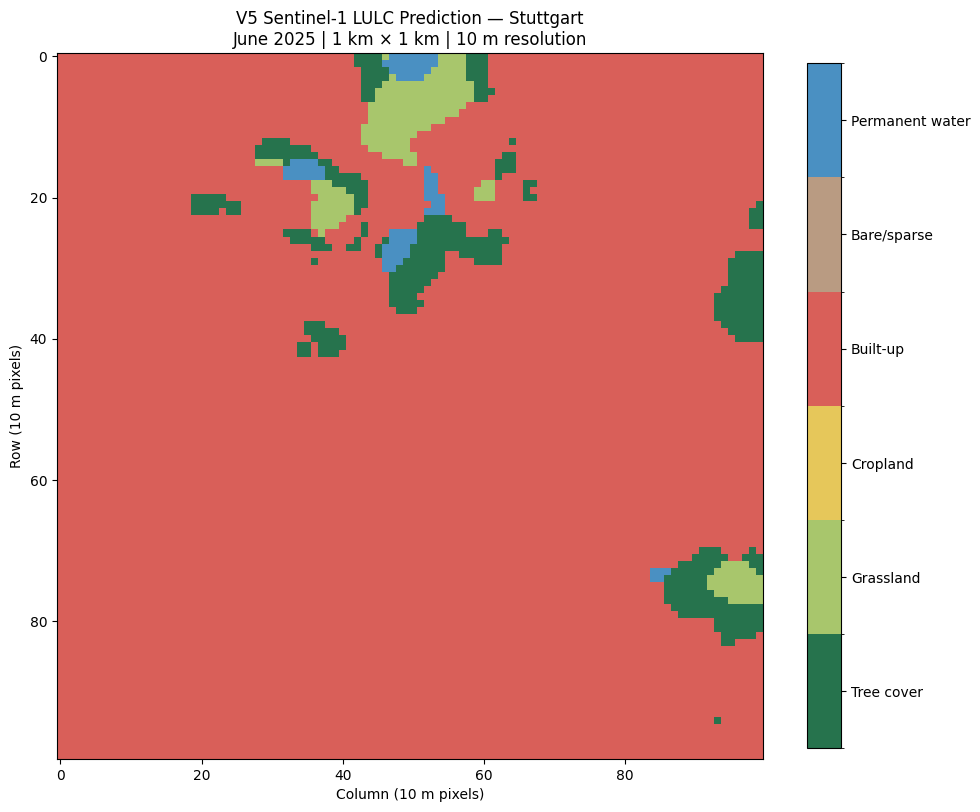

In [42]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

colors = [
    "#26734D",  # Tree cover
    "#A8C66C",  # Grassland
    "#E6C75A",  # Cropland
    "#D95F59",  # Built-up
    "#B99B82",  # Bare/sparse vegetation
    "#4A90C2",  # Permanent water
]

cmap = ListedColormap(colors)
norm = BoundaryNorm(
    np.arange(0.5, 7.5, 1),
    cmap.N
)

fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(
    prediction,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

ax.set_title(
    "V5 Sentinel-1 LULC Prediction — Stuttgart\n"
    "June 2025 | 1 km × 1 km | 10 m resolution"
)
ax.set_xlabel("Column (10 m pixels)")
ax.set_ylabel("Row (10 m pixels)")

cbar = fig.colorbar(
    im,
    ax=ax,
    ticks=np.arange(1, 7),
    shrink=0.8
)

cbar.ax.set_yticklabels([
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse",
    "Permanent water"
])

plt.tight_layout()
plt.show()


In [43]:
from datetime import date
import calendar
import ee

# Test starting month — change these values to test other periods
start_year = 2025
start_month = 10

# Generate 12 consecutive calendar months
monthly_schedule = []

for offset in range(12):
    month_index = start_year * 12 + (start_month - 1) + offset
    year = month_index // 12
    month = month_index % 12 + 1

    start_date = date(year, month, 1)

    if month == 12:
        end_date = date(year + 1, 1, 1)
    else:
        end_date = date(year, month + 1, 1)

    monthly_schedule.append({
        "label": start_date.strftime("%Y-%m"),
        "start": start_date.isoformat(),
        "end": end_date.isoformat()
    })

# Only allow fully completed calendar months
current_month_start = date.today().replace(day=1)
period_end = date.fromisoformat(monthly_schedule[-1]["end"])

if period_end > current_month_start:
    raise ValueError(
        "The selected 12-month period includes an incomplete or future month. "
        "Choose an earlier starting month."
    )

# Build the Sentinel-1 collection
s1_collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(point)
    .filter(ee.Filter.eq("instrumentMode", "IW"))
    .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
)

# Check the number of scenes in each month
print("12-MONTH SENTINEL-1 AVAILABILITY CHECK")
print("=" * 55)

for item in monthly_schedule:
    count = (
        s1_collection
        .filterDate(item["start"], item["end"])
        .size()
        .getInfo()
    )

    item["scene_count"] = count

    if count == 0:
        status = "NO DATA"
    elif count < 3:
        status = "LIMITED OBSERVATIONS"
    else:
        status = "SCENES AVAILABLE"

    print(
        f"{item['label']} | "
        f"{count:2d} scenes | {status}"
    )

print("=" * 55)
print("Months checked:", len(monthly_schedule))
print("Starting month:", monthly_schedule[0]["label"])
print("Ending month:", monthly_schedule[-1]["label"])

12-MONTH SENTINEL-1 AVAILABILITY CHECK
2025-10 |  5 scenes | SCENES AVAILABLE
2025-11 |  4 scenes | SCENES AVAILABLE
2025-12 |  5 scenes | SCENES AVAILABLE
2026-01 |  5 scenes | SCENES AVAILABLE
2026-02 |  5 scenes | SCENES AVAILABLE
2026-03 |  5 scenes | SCENES AVAILABLE
2026-04 |  6 scenes | SCENES AVAILABLE
2026-05 |  6 scenes | SCENES AVAILABLE
2026-06 |  6 scenes | SCENES AVAILABLE
2026-07 |  5 scenes | SCENES AVAILABLE
2026-08 |  6 scenes | SCENES AVAILABLE
2026-09 |  5 scenes | SCENES AVAILABLE
Months checked: 12
Starting month: 2025-10
Ending month: 2026-09


In [44]:
print("MONTHLY SPATIAL COVERAGE CHECK")
print("=" * 60)

for item in monthly_schedule:

    monthly_collection = (
        s1_collection
        .filterDate(item["start"], item["end"])
        .select(["VV", "VH"])
    )

    monthly_composite = (
        monthly_collection
        .median()
        .setDefaultProjection(test_grid["projection"])
    )

    coverage = (
        monthly_composite
        .reduceRegion(
            reducer=ee.Reducer.count(),
            geometry=region,
            crs=test_grid["crs"],
            crsTransform=test_grid["transform"],
            maxPixels=100000
        )
        .getInfo()
    )

    vv_count = coverage.get("VV", 0) or 0
    vh_count = coverage.get("VH", 0) or 0

    expected_pixels = test_grid["width"] * test_grid["height"]

    vv_percentage = vv_count / expected_pixels * 100
    vh_percentage = vh_count / expected_pixels * 100

    item["vv_coverage"] = vv_percentage
    item["vh_coverage"] = vh_percentage

    print(
        f"{item['label']} | "
        f"VV: {vv_percentage:.2f}% | "
        f"VH: {vh_percentage:.2f}%"
    )

print("=" * 60)

MONTHLY SPATIAL COVERAGE CHECK
2025-10 | VV: 100.00% | VH: 100.00%
2025-11 | VV: 100.00% | VH: 100.00%
2025-12 | VV: 100.00% | VH: 100.00%
2026-01 | VV: 100.00% | VH: 100.00%
2026-02 | VV: 100.00% | VH: 100.00%
2026-03 | VV: 100.00% | VH: 100.00%
2026-04 | VV: 100.00% | VH: 100.00%
2026-05 | VV: 100.00% | VH: 100.00%
2026-06 | VV: 100.00% | VH: 100.00%
2026-07 | VV: 100.00% | VH: 100.00%
2026-08 | VV: 100.00% | VH: 100.00%
2026-09 | VV: 100.00% | VH: 100.00%


In [45]:
import requests
import rasterio
import numpy as np
from pathlib import Path

# Output directory
monthly_input_dir = (
    project_root / "arbitrary_location_test" / "monthly_inputs"
)
monthly_input_dir.mkdir(parents=True, exist_ok=True)

download_results = []

for item in monthly_schedule:

    label = item["label"]

    print(f"\nProcessing {label}...")

    # Monthly median composite
    monthly_composite = (
        s1_collection
        .filterDate(item["start"], item["end"])
        .select(["VV", "VH"])
        .median()
        .setDefaultProjection(test_grid["projection"])
    )

    # Exact export grid
    download_params = {
        "name": f"sentinel1_{label}",
        "bands": ["VV", "VH"],
        "region": region,
        "crs": test_grid["crs"],
        "crs_transform": test_grid["transform"],
        "format": "GEO_TIFF"
    }

    # Generate Earth Engine download URL
    url = monthly_composite.getDownloadURL(download_params)

    # Download raster
    response = requests.get(url, timeout=180)
    response.raise_for_status()

    output_path = (
        monthly_input_dir / f"sentinel1_vv_vh_{label}.tif"
    )

    output_path.write_bytes(response.content)

    # Validate downloaded raster
    with rasterio.open(output_path) as src:

        data = src.read()

        valid = (
            src.count == 2
            and src.width == test_grid["width"]
            and src.height == test_grid["height"]
            and str(src.crs) == test_grid["crs"]
            and np.isfinite(data).all()
            and np.all(src.dataset_mask() > 0)
        )

        if not valid:
            raise ValueError(
                f"Validation failed for {label}: "
                f"{src.width}x{src.height}, {src.crs}"
            )

        download_results.append({
            "month": label,
            "file": output_path.name,
            "shape": data.shape,
            "size_mb": round(output_path.stat().st_size / 1024**2, 3),
            "valid": valid
        })

    print(
        f"  Saved: {output_path.name} | "
        f"{data.shape} | "
        f"{output_path.stat().st_size / 1024**2:.3f} MB | "
        f"Valid: {valid}"
    )

print("\n" + "=" * 65)
print("MONTHLY DOWNLOAD SUMMARY")
print("=" * 65)

for result in download_results:
    print(result)

print("\nTotal downloaded:", len(download_results))
print("All valid:", all(r["valid"] for r in download_results))


Processing 2025-10...
  Saved: sentinel1_vv_vh_2025-10.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2025-11...
  Saved: sentinel1_vv_vh_2025-11.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2025-12...
  Saved: sentinel1_vv_vh_2025-12.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-01...
  Saved: sentinel1_vv_vh_2026-01.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-02...
  Saved: sentinel1_vv_vh_2026-02.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-03...
  Saved: sentinel1_vv_vh_2026-03.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-04...
  Saved: sentinel1_vv_vh_2026-04.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-05...
  Saved: sentinel1_vv_vh_2026-05.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-06...
  Saved: sentinel1_vv_vh_2026-06.tif | (2, 100, 100) | 0.149 MB | Valid: True

Processing 2026-07...
  Saved: sentinel1_vv_vh_2026-07.tif | (2, 100, 100) | 0.149 MB | Va

In [46]:
from pathlib import Path
import rasterio
import numpy as np

from src.inference import predict_raster

monthly_prediction_dir = (
    project_root / "arbitrary_location_test" / "monthly_predictions"
)
monthly_prediction_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = project_root / "outputs" / "best_unet_v5.pt"

prediction_results = []

for item in monthly_schedule:

    label = item["label"]

    input_path = (
        monthly_input_dir / f"sentinel1_vv_vh_{label}.tif"
    )

    output_path = (
        monthly_prediction_dir / f"lulc_v5_{label}.tif"
    )

    print(f"\nPredicting {label}...")

    predict_raster(
        input_path=input_path,
        output_path=output_path,
        checkpoint_path=checkpoint_path,
        batch_size=16,
        patch_size=128
    )

    with rasterio.open(output_path) as src:
        prediction = src.read(1)

        valid_classes = np.isin(prediction, [1, 2, 3, 4, 5, 6])

        if (
            prediction.shape != (100, 100)
            or not valid_classes.all()
            or src.crs.to_string() != test_grid["crs"]
        ):
            raise ValueError(f"Prediction validation failed: {label}")

        prediction_results.append({
            "month": label,
            "file": output_path.name,
            "pixels": prediction.size,
            "valid_pixels": int(valid_classes.sum()),
            "valid": True
        })

    print(f"  Saved: {output_path.name}")
    print("  Valid pixels:", int(valid_classes.sum()))

print("\n" + "=" * 60)
print("MONTHLY INFERENCE SUMMARY")
print("=" * 60)

for result in prediction_results:
    print(result)

print("\nTotal predictions:", len(prediction_results))
print("All valid:", all(r["valid"] for r in prediction_results))



Predicting 2025-10...
  Saved: lulc_v5_2025-10.tif
  Valid pixels: 10000

Predicting 2025-11...
  Saved: lulc_v5_2025-11.tif
  Valid pixels: 10000

Predicting 2025-12...
  Saved: lulc_v5_2025-12.tif
  Valid pixels: 10000

Predicting 2026-01...
  Saved: lulc_v5_2026-01.tif
  Valid pixels: 10000

Predicting 2026-02...
  Saved: lulc_v5_2026-02.tif
  Valid pixels: 10000

Predicting 2026-03...
  Saved: lulc_v5_2026-03.tif
  Valid pixels: 10000

Predicting 2026-04...
  Saved: lulc_v5_2026-04.tif
  Valid pixels: 10000

Predicting 2026-05...
  Saved: lulc_v5_2026-05.tif
  Valid pixels: 10000

Predicting 2026-06...
  Saved: lulc_v5_2026-06.tif
  Valid pixels: 10000

Predicting 2026-07...
  Saved: lulc_v5_2026-07.tif
  Valid pixels: 10000

Predicting 2026-08...
  Saved: lulc_v5_2026-08.tif
  Valid pixels: 10000

Predicting 2026-09...
  Saved: lulc_v5_2026-09.tif
  Valid pixels: 10000

MONTHLY INFERENCE SUMMARY
{'month': '2025-10', 'file': 'lulc_v5_2025-10.tif', 'pixels': 10000, 'valid_pixels': 

In [47]:
import pandas as pd
import rasterio
import numpy as np

CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

monthly_maps = {}
monthly_statistics = []

pixel_area_m2 = 100
total_area_ha = 100  # 1 km²

for item in monthly_schedule:

    month = item["label"]

    prediction_path = (
        monthly_prediction_dir / f"lulc_v5_{month}.tif"
    )

    with rasterio.open(prediction_path) as src:
        lulc_map = src.read(1)

    monthly_maps[month] = lulc_map

    total_pixels = lulc_map.size

    for class_id, class_name in CLASS_NAMES.items():

        pixel_count = int(np.sum(lulc_map == class_id))

        percentage = pixel_count / total_pixels * 100

        area_ha = pixel_count * pixel_area_m2 / 10000

        monthly_statistics.append({
            "Month": month,
            "Class": class_name,
            "Pixels": pixel_count,
            "Percentage": round(percentage, 3),
            "Area_ha": round(area_ha, 3)
        })

statistics_df = pd.DataFrame(monthly_statistics)

print("MONTHLY LULC CLASS DISTRIBUTION")
print("=" * 75)

print(
    statistics_df.pivot(
        index="Month",
        columns="Class",
        values="Percentage"
    ).round(2).to_string()
)

print("\nAREA SUMMARY")
print("=" * 75)

print(
    statistics_df.pivot(
        index="Month",
        columns="Class",
        values="Area_ha"
    ).round(2).to_string()
)

print("\nTotal months:", len(monthly_maps))
print("Total pixels per month:", next(iter(monthly_maps.values())).size)
print("Study area:", total_area_ha, "hectares")

MONTHLY LULC CLASS DISTRIBUTION
Class    Bare/sparse vegetation  Built-up  Cropland  Grassland  Permanent water  Tree cover
Month                                                                                      
2025-10                     0.0     93.97       0.0       1.56             0.62        3.85
2025-11                     0.0     92.86       0.0       2.24             0.42        4.48
2025-12                     0.0     93.67       0.0       1.68             0.42        4.23
2026-01                     0.0     93.25       0.0       2.12             0.23        4.40
2026-02                     0.0     93.60       0.0       1.68             0.43        4.29
2026-03                     0.0     93.49       0.0       1.93             0.09        4.49
2026-04                     0.0     90.19       0.0       3.24             0.99        5.58
2026-05                     0.0     91.87       0.0       2.11             0.68        5.34
2026-06                     0.0     91.50       

In [48]:
import pandas as pd
import numpy as np

class_ids = [1, 2, 3, 4, 5, 6]
class_names_ordered = [
    CLASS_NAMES[i] for i in class_ids
]

def transition_matrix(previous_map, current_map):
    matrix = np.zeros((6, 6), dtype=np.int64)

    for old_id, new_id in zip(
        previous_map.ravel(),
        current_map.ravel()
    ):
        if old_id in class_ids and new_id in class_ids:
            matrix[old_id - 1, new_id - 1] += 1

    return pd.DataFrame(
        matrix,
        index=class_names_ordered,
        columns=class_names_ordered
    )

# First month vs last month
first_month = monthly_schedule[0]["label"]
last_month = monthly_schedule[-1]["label"]

first_map = monthly_maps[first_month]
last_map = monthly_maps[last_month]

overall_matrix = transition_matrix(first_map, last_map)

print("TRANSITION MATRIX")
print(f"{first_month} → {last_month}")
print("Rows = previous class | Columns = new class\n")

print(overall_matrix.to_string())

# Changed and unchanged pixels
changed_pixels = int(np.sum(first_map != last_map))
total_pixels = first_map.size
unchanged_pixels = total_pixels - changed_pixels

print("\nOVERALL CHANGE")
print("Total pixels:", total_pixels)
print("Changed pixels:", changed_pixels)
print("Unchanged pixels:", unchanged_pixels)
print("Changed percentage:", round(changed_pixels / total_pixels * 100, 2))
print("Changed area (hectares):", round(changed_pixels / 100, 2))

# Month-to-month transitions
print("\nMONTH-TO-MONTH PIXEL CHANGES")

for i in range(1, len(monthly_schedule)):
    previous = monthly_schedule[i - 1]["label"]
    current = monthly_schedule[i]["label"]

    old_map = monthly_maps[previous]
    new_map = monthly_maps[current]

    changed = int(np.sum(old_map != new_map))

    print(
        f"{previous} → {current}: "
        f"{changed} pixels "
        f"({changed / total_pixels * 100:.2f}%)"
    )
    

TRANSITION MATRIX
2025-10 → 2026-09
Rows = previous class | Columns = new class

                        Tree cover  Grassland  Cropland  Built-up  Bare/sparse vegetation  Permanent water
Tree cover                     211         24         0       149                       0                1
Grassland                        0        136         0        15                       0                5
Cropland                         0          0         0         0                       0                0
Built-up                        33        117         0      9246                       0                1
Bare/sparse vegetation           0          0         0         0                       0                0
Permanent water                  1          8         0        22                       0               31

OVERALL CHANGE
Total pixels: 10000
Changed pixels: 376
Unchanged pixels: 9624
Changed percentage: 3.76
Changed area (hectares): 3.76

MONTH-TO-MONTH PIXEL CHANGES
2025-1

Animation saved: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/arbitrary_location_test/lulc_12_month_animation.gif


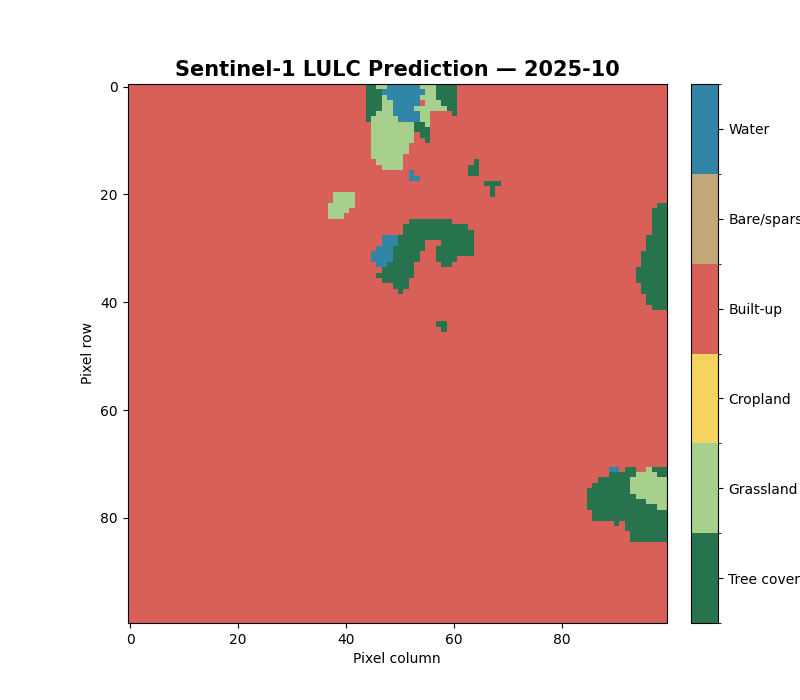

In [49]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import Image, display
from pathlib import Path

# Consistent colors for all months
class_colors = [
    "#26734D",  # 1 Tree cover
    "#A8D08D",  # 2 Grassland
    "#F4D35E",  # 3 Cropland
    "#D95F59",  # 4 Built-up
    "#C2A878",  # 5 Bare/sparse vegetation
    "#3185A6"   # 6 Permanent water
]

cmap = ListedColormap(class_colors)
norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5],
    cmap.N
)

months = [item["label"] for item in monthly_schedule]

animation_dir = project_root / "arbitrary_location_test"
animation_dir.mkdir(parents=True, exist_ok=True)

gif_path = animation_dir / "lulc_12_month_animation.gif"

fig, ax = plt.subplots(figsize=(8, 7))

image_plot = ax.imshow(
    monthly_maps[months[0]],
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

title = ax.set_title(months[0], fontsize=15, weight="bold")
ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")

colorbar = fig.colorbar(
    image_plot,
    ax=ax,
    ticks=[1, 2, 3, 4, 5, 6],
    fraction=0.046,
    pad=0.04
)

colorbar.ax.set_yticklabels([
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse",
    "Water"
])

def update(frame):
    month = months[frame]

    image_plot.set_data(monthly_maps[month])
    title.set_text(f"Sentinel-1 LULC Prediction — {month}")

    return image_plot, title

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(months),
    interval=900,
    blit=False,
    repeat=True
)

ani.save(
    gif_path,
    writer=animation.PillowWriter(fps=1)
)

plt.close(fig)

print("Animation saved:", gif_path)
display(Image(filename=str(gif_path)))

In [50]:
from datetime import date
import calendar
import ee

# ==========================================
# USER CONFIGURATION
# ==========================================

run_config = {
    "latitude": 48.7758,
    "longitude": 9.1829,

    # First month of the 12-month analysis
    "start_year": 2025,
    "start_month": 10,

    # Study area dimensions
    "area_size_m": 1000,   # 1 km x 1 km for testing
    "pixel_size_m": 10,

    # Sentinel-1 settings
    "orbit_pass": "DESCENDING",
    "instrument_mode": "IW",
    "polarisation": ["VV", "VH"]
}

# ==========================================
# INPUT VALIDATION
# ==========================================

lat = run_config["latitude"]
lon = run_config["longitude"]
year = run_config["start_year"]
month = run_config["start_month"]

assert -90 <= lat <= 90, "Latitude must be between -90 and 90."
assert -180 <= lon <= 180, "Longitude must be between -180 and 180."
assert 1 <= month <= 12, "Starting month must be between 1 and 12."
assert run_config["area_size_m"] > 0
assert run_config["pixel_size_m"] > 0

# Calculate the final month
start_index = year * 12 + month - 1
end_index = start_index + 11

end_year = end_index // 12
end_month = end_index % 12 + 1

# Do not request an incomplete or future month
today = date.today()
latest_complete_index = today.year * 12 + today.month - 2

assert end_index <= latest_complete_index, (
    f"Requested period ends in {end_year}-{end_month:02d}, "
    "which is not yet a complete month."
)

# ==========================================
# GENERATE 12-MONTH SCHEDULE
# ==========================================

run_schedule = []

for offset in range(12):
    current_index = start_index + offset

    current_year = current_index // 12
    current_month = current_index % 12 + 1

    last_day = calendar.monthrange(
        current_year,
        current_month
    )[1]

    run_schedule.append({
        "label": f"{current_year}-{current_month:02d}",
        "start": f"{current_year}-{current_month:02d}-01",
        "end": (
            f"{current_year}-{current_month:02d}-{last_day:02d}"
        )
    })

# ==========================================
# CREATE LOCATION AND STUDY AREA
# ==========================================

run_point = ee.Geometry.Point([lon, lat])

run_grid = create_utm_grid(
    latitude=lat,
    longitude=lon,
    area_size_m=run_config["area_size_m"],
    pixel_size_m=run_config["pixel_size_m"]
)

left, bottom, right, top = run_grid["bounds"]

run_region = ee.Geometry.Rectangle(
    [left, bottom, right, top],
    proj=run_grid["crs"],
    geodesic=False
)

# ==========================================
# DISPLAY CONFIGURATION
# ==========================================

print("LOCATION CONFIGURATION")
print("=" * 50)
print(f"Latitude:       {lat}")
print(f"Longitude:      {lon}")
print(f"Study area:     {run_config['area_size_m']} m x {run_config['area_size_m']} m")
print(f"Pixel size:     {run_config['pixel_size_m']} m")
print(f"CRS:            {run_grid['crs']}")

print("\nANALYSIS PERIOD")
print("=" * 50)
print("First month:", run_schedule[0]["label"])
print("Last month: ", run_schedule[-1]["label"])
print("Total months:", len(run_schedule))

print("\nMONTHLY SCHEDULE")
for item in run_schedule:
    print(item["label"], item["start"], "to", item["end"])

LOCATION CONFIGURATION
Latitude:       48.7758
Longitude:      9.1829
Study area:     1000 m x 1000 m
Pixel size:     10 m
CRS:            EPSG:32632

ANALYSIS PERIOD
First month: 2025-10
Last month:  2026-09
Total months: 12

MONTHLY SCHEDULE
2025-10 2025-10-01 to 2025-10-31
2025-11 2025-11-01 to 2025-11-30
2025-12 2025-12-01 to 2025-12-31
2026-01 2026-01-01 to 2026-01-31
2026-02 2026-02-01 to 2026-02-28
2026-03 2026-03-01 to 2026-03-31
2026-04 2026-04-01 to 2026-04-30
2026-05 2026-05-01 to 2026-05-31
2026-06 2026-06-01 to 2026-06-30
2026-07 2026-07-01 to 2026-07-31
2026-08 2026-08-01 to 2026-08-31
2026-09 2026-09-01 to 2026-09-30


In [51]:
import ee
import pandas as pd

# ==========================================
# BUILD GENERAL SENTINEL-1 COLLECTION
# ==========================================

run_collection = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterBounds(run_region)
    .filter(ee.Filter.eq(
        "instrumentMode",
        run_config["instrument_mode"]
    ))
    .filter(ee.Filter.eq(
        "orbitProperties_pass",
        run_config["orbit_pass"]
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VV"
    ))
    .filter(ee.Filter.listContains(
        "transmitterReceiverPolarisation", "VH"
    ))
)

# ==========================================
# CHECK EACH MONTH
# ==========================================

availability_results = []

expected_pixels = (
    run_grid["width"] * run_grid["height"]
)

for item in run_schedule:

    month = item["label"]

    start_date = ee.Date(item["start"])
    end_date = start_date.advance(1, "month")

    monthly_collection = (
        run_collection
        .filterDate(start_date, end_date)
    )

    scene_count = monthly_collection.size().getInfo()

    if scene_count == 0:
        availability_results.append({
            "Month": month,
            "Scenes": 0,
            "Valid_pixels": 0,
            "Coverage_pct": 0.0,
            "Status": "NO DATA"
        })
        continue

    # Monthly median composite
    composite = monthly_collection.select(
        ["VV", "VH"]
    ).median()

    # A pixel is valid only when both VV and VH are valid
    valid_mask = (
        composite.select("VV").mask()
        .And(composite.select("VH").mask())
    )

    valid_pixel_count = (
        ee.Image.constant(1)
        .updateMask(valid_mask)
        .reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=run_region,
            scale=run_config["pixel_size_m"],
            crs=run_grid["crs"],
            maxPixels=100_000_000,
            tileScale=4
        )
        .get("constant")
        .getInfo()
    )

    valid_pixel_count = int(valid_pixel_count or 0)

    coverage_pct = (
        valid_pixel_count / expected_pixels * 100
    )

    status = (
        "OK" if coverage_pct >= 99
        else "PARTIAL COVERAGE"
        if coverage_pct > 0
        else "NO SPATIAL COVERAGE"
    )

    availability_results.append({
        "Month": month,
        "Scenes": scene_count,
        "Valid_pixels": valid_pixel_count,
        "Coverage_pct": round(coverage_pct, 2),
        "Status": status
    })

# ==========================================
# DISPLAY RESULTS
# ==========================================

availability_df = pd.DataFrame(availability_results)

print("SENTINEL-1 DATA AVAILABILITY")
print("=" * 75)
print(availability_df.to_string(index=False))

print("\nSUMMARY")
print("=" * 75)
print("Months checked:", len(availability_df))
print(
    "Months with scenes:",
    int((availability_df["Scenes"] > 0).sum())
)
print(
    "Months with at least 99% coverage:",
    int((availability_df["Coverage_pct"] >= 99).sum())
)
print(
    "Minimum spatial coverage:",
    availability_df["Coverage_pct"].min(),
    "%"
)

SENTINEL-1 DATA AVAILABILITY
  Month  Scenes  Valid_pixels  Coverage_pct Status
2025-10       5         10000         100.0     OK
2025-11       4         10000         100.0     OK
2025-12       5         10000         100.0     OK
2026-01       5         10000         100.0     OK
2026-02       5         10000         100.0     OK
2026-03       5         10000         100.0     OK
2026-04       6         10000         100.0     OK
2026-05       6         10000         100.0     OK
2026-06       6         10000         100.0     OK
2026-07       5         10000         100.0     OK
2026-08       6         10000         100.0     OK
2026-09       5         10000         100.0     OK

SUMMARY
Months checked: 12
Months with scenes: 12
Months with at least 99% coverage: 12
Minimum spatial coverage: 100.0 %


In [52]:
orbit_results = []

for item in run_schedule:

    start_date = ee.Date(item["start"])
    end_date = start_date.advance(1, "month")

    monthly_collection = run_collection.filterDate(
        start_date,
        end_date
    )

    orbit_counts = (
        monthly_collection
        .aggregate_histogram("relativeOrbitNumber_start")
        .getInfo()
    )

    orbit_results.append({
        "Month": item["label"],
        "Orbit_counts": orbit_counts
    })

print("RELATIVE ORBIT DISTRIBUTION")
print("=" * 65)

for result in orbit_results:
    print(f"\n{result['Month']}")
    print(result["Orbit_counts"])

# Summarize orbit coverage across all months
all_orbits = sorted({
    orbit
    for result in orbit_results
    for orbit in result["Orbit_counts"]
})

orbit_summary = []

for orbit in all_orbits:
    monthly_counts = [
        result["Orbit_counts"].get(str(orbit), 0)
        for result in orbit_results
    ]

    orbit_summary.append({
        "Relative_orbit": orbit,
        "Months_covered": sum(count > 0 for count in monthly_counts),
        "Total_scenes": sum(monthly_counts),
        "Monthly_scene_counts": monthly_counts
    })

orbit_summary_df = pd.DataFrame(orbit_summary)

print("\nORBIT COVERAGE SUMMARY")
print("=" * 65)

print(
    orbit_summary_df[
        ["Relative_orbit", "Months_covered", "Total_scenes"]
    ].to_string(index=False)
)

RELATIVE ORBIT DISTRIBUTION

2025-10
{'66.0': 5}

2025-11
{'66.0': 4}

2025-12
{'66.0': 5}

2026-01
{'66.0': 5}

2026-02
{'66.0': 5}

2026-03
{'66.0': 5}

2026-04
{'66.0': 6}

2026-05
{'66.0': 6}

2026-06
{'66.0': 6}

2026-07
{'66.0': 5}

2026-08
{'66.0': 6}

2026-09
{'66.0': 5}

ORBIT COVERAGE SUMMARY
Relative_orbit  Months_covered  Total_scenes
          66.0              12            63


In [53]:
# ==========================================
# SELECT CONSISTENT RELATIVE ORBIT
# ==========================================

selected_orbit = 66

run_collection_orbit = run_collection.filter(
    ee.Filter.eq(
        "relativeOrbitNumber_start",
        selected_orbit
    )
)

print("Selected relative orbit:", selected_orbit)

# Verify monthly scene availability after filtering
orbit_verification = []

for item in run_schedule:

    start_date = ee.Date(item["start"])
    end_date = start_date.advance(1, "month")

    count = (
        run_collection_orbit
        .filterDate(start_date, end_date)
        .size()
        .getInfo()
    )

    orbit_verification.append({
        "Month": item["label"],
        "Scenes": count
    })

orbit_verification_df = pd.DataFrame(orbit_verification)

print("\nORBIT-SPECIFIC AVAILABILITY")
print(orbit_verification_df.to_string(index=False))

if not (orbit_verification_df["Scenes"] > 0).all():
    raise RuntimeError(
        "Selected orbit does not cover every requested month."
    )

print("\nSUCCESS: Selected orbit covers all 12 months.")

Selected relative orbit: 66

ORBIT-SPECIFIC AVAILABILITY
  Month  Scenes
2025-10       5
2025-11       4
2025-12       5
2026-01       5
2026-02       5
2026-03       5
2026-04       6
2026-05       6
2026-06       6
2026-07       5
2026-08       6
2026-09       5

SUCCESS: Selected orbit covers all 12 months.


In [54]:
import requests
import rasterio
import numpy as np
from pathlib import Path

# ==========================================
# OUTPUT DIRECTORY
# ==========================================

run_input_dir = (
    project_root
    / "arbitrary_location_test"
    / "configurable_monthly_inputs"
)

run_input_dir.mkdir(parents=True, exist_ok=True)

# ==========================================
# DOWNLOAD MONTHLY COMPOSITES
# ==========================================

download_results = []

for item in run_schedule:

    month = item["label"]

    start_date = ee.Date(item["start"])
    end_date = start_date.advance(1, "month")

    monthly_collection = (
        run_collection_orbit
        .filterDate(start_date, end_date)
    )

    scene_count = monthly_collection.size().getInfo()

    if scene_count == 0:
        raise RuntimeError(f"No Sentinel-1 scenes for {month}")

    composite = (
        monthly_collection
        .select(["VV", "VH"])
        .median()
        .setDefaultProjection(run_grid["projection"])
    )

    output_path = (
        run_input_dir / f"sentinel1_vv_vh_{month}.tif"
    )

    download_url = composite.getDownloadURL({
        "name": f"sentinel1_vv_vh_{month}",
        "bands": ["VV", "VH"],
        "region": run_region,
        "crs": run_grid["crs"],
        "crs_transform": run_grid["transform"],
        "format": "GEO_TIFF"
    })

    response = requests.get(download_url, timeout=180)
    response.raise_for_status()

    output_path.write_bytes(response.content)

    # Validate downloaded raster
    with rasterio.open(output_path) as src:

        data = src.read()

        valid = np.isfinite(data).all(axis=0)

        result = {
            "Month": month,
            "Scenes": scene_count,
            "Shape": data.shape,
            "CRS": src.crs.to_string(),
            "Resolution": src.res,
            "Valid_pixels": int(valid.sum()),
            "File_MB": round(
                output_path.stat().st_size / (1024 ** 2), 3
            ),
            "Status": "OK" if valid.all() else "CHECK NODATA"
        }

    download_results.append(result)

    print(
        f"{month}: downloaded | "
        f"{scene_count} scenes | "
        f"{result['Status']}"
    )

# ==========================================
# SUMMARY
# ==========================================

download_df = pd.DataFrame(download_results)

print("\nDOWNLOAD VALIDATION")
print("=" * 85)
print(download_df.to_string(index=False))

print("\nTotal files:", len(download_results))
print("Output directory:", run_input_dir)

2025-10: downloaded | 5 scenes | OK
2025-11: downloaded | 4 scenes | OK
2025-12: downloaded | 5 scenes | OK
2026-01: downloaded | 5 scenes | OK
2026-02: downloaded | 5 scenes | OK
2026-03: downloaded | 5 scenes | OK
2026-04: downloaded | 6 scenes | OK
2026-05: downloaded | 6 scenes | OK
2026-06: downloaded | 6 scenes | OK
2026-07: downloaded | 5 scenes | OK
2026-08: downloaded | 6 scenes | OK
2026-09: downloaded | 5 scenes | OK

DOWNLOAD VALIDATION
  Month  Scenes         Shape        CRS   Resolution  Valid_pixels  File_MB Status
2025-10       5 (2, 100, 100) EPSG:32632 (10.0, 10.0)         10000    0.149     OK
2025-11       4 (2, 100, 100) EPSG:32632 (10.0, 10.0)         10000    0.149     OK
2025-12       5 (2, 100, 100) EPSG:32632 (10.0, 10.0)         10000    0.149     OK
2026-01       5 (2, 100, 100) EPSG:32632 (10.0, 10.0)         10000    0.149     OK
2026-02       5 (2, 100, 100) EPSG:32632 (10.0, 10.0)         10000    0.149     OK
2026-03       5 (2, 100, 100) EPSG:32632 (1

In [55]:
import inspect
from src.inference import predict_raster

print(inspect.signature(predict_raster))

(input_path, output_path, checkpoint_path, batch_size=16, patch_size=128, device=None)


In [57]:
from src.inference import predict_raster
from pathlib import Path
import rasterio
import numpy as np
import pandas as pd
import torch

# ==========================================
# CONFIGURATION
# ==========================================

run_prediction_dir = (
    project_root
    / "arbitrary_location_test"
    / "configurable_monthly_predictions"
)

run_prediction_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = project_root / "outputs" / "best_unet_v5.pt"

assert checkpoint_path.exists(), (
    f"Checkpoint not found: {checkpoint_path}"
)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Checkpoint:", checkpoint_path)
print("Device:", device)

# ==========================================
# RUN MONTHLY INFERENCE
# ==========================================

inference_results = []

for item in run_schedule:

    month = item["label"]

    input_path = (
        run_input_dir / f"sentinel1_vv_vh_{month}.tif"
    )

    output_path = (
        run_prediction_dir / f"lulc_v5_{month}.tif"
    )

    if not input_path.exists():
        raise FileNotFoundError(input_path)

    predict_raster(
        input_path=str(input_path),
        output_path=str(output_path),
        checkpoint_path=str(checkpoint_path),
        batch_size=16,
        patch_size=128,
        device=device
    )

    # Validate prediction
    with rasterio.open(output_path) as src:
        prediction = src.read(1)

        unique_classes = np.unique(prediction)
        valid_pixels = int(np.isin(
            prediction, [1, 2, 3, 4, 5, 6]
        ).sum())

        inference_results.append({
            "Month": month,
            "Shape": prediction.shape,
            "Valid_pixels": valid_pixels,
            "Classes_found": unique_classes.tolist(),
            "CRS": src.crs.to_string(),
            "Status": (
                "OK"
                if valid_pixels == prediction.size
                else "CHECK"
            )
        })

    print(f"{month}: inference completed")

# ==========================================
# SUMMARY
# ==========================================

inference_df = pd.DataFrame(inference_results)

print("\nINFERENCE VALIDATION")
print("=" * 85)
print(inference_df.to_string(index=False))

print("\nTotal predictions:", len(inference_results))
print("Output directory:", run_prediction_dir)

Checkpoint: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/outputs/best_unet_v5.pt
Device: cuda
2025-10: inference completed
2025-11: inference completed
2025-12: inference completed
2026-01: inference completed
2026-02: inference completed
2026-03: inference completed
2026-04: inference completed
2026-05: inference completed
2026-06: inference completed
2026-07: inference completed
2026-08: inference completed
2026-09: inference completed

INFERENCE VALIDATION
  Month      Shape  Valid_pixels Classes_found        CRS Status
2025-10 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2025-11 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2025-12 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2026-01 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2026-02 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2026-03 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2026-04 (100, 100)         10000  [1, 2, 4, 6] EPSG:32632     OK
2026-0

In [58]:
import rasterio
import numpy as np
import pandas as pd

CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

run_monthly_maps = {}
run_monthly_statistics = []

pixel_area_m2 = run_config["pixel_size_m"] ** 2

total_pixels = (
    run_grid["width"] * run_grid["height"]
)

total_area_ha = (
    total_pixels * pixel_area_m2 / 10000
)

for item in run_schedule:

    month = item["label"]

    prediction_path = (
        run_prediction_dir / f"lulc_v5_{month}.tif"
    )

    with rasterio.open(prediction_path) as src:
        lulc_map = src.read(1)

    run_monthly_maps[month] = lulc_map

    for class_id, class_name in CLASS_NAMES.items():

        pixel_count = int(
            np.sum(lulc_map == class_id)
        )

        percentage = (
            pixel_count / total_pixels * 100
        )

        area_ha = (
            pixel_count * pixel_area_m2 / 10000
        )

        run_monthly_statistics.append({
            "Month": month,
            "Class": class_name,
            "Pixels": pixel_count,
            "Percentage": round(percentage, 3),
            "Area_ha": round(area_ha, 3)
        })

run_statistics_df = pd.DataFrame(
    run_monthly_statistics
)

print("MONTHLY LULC CLASS DISTRIBUTION")
print("=" * 75)

print(
    run_statistics_df.pivot(
        index="Month",
        columns="Class",
        values="Percentage"
    ).round(2).to_string()
)

print("\nAREA SUMMARY (HECTARES)")
print("=" * 75)

print(
    run_statistics_df.pivot(
        index="Month",
        columns="Class",
        values="Area_ha"
    ).round(2).to_string()
)

print("\nVALIDATION")
print("Months:", len(run_monthly_maps))
print("Pixels per month:", total_pixels)
print("Study area:", total_area_ha, "hectares")

MONTHLY LULC CLASS DISTRIBUTION
Class    Bare/sparse vegetation  Built-up  Cropland  Grassland  Permanent water  Tree cover
Month                                                                                      
2025-10                     0.0     93.97       0.0       1.56             0.62        3.85
2025-11                     0.0     92.86       0.0       2.24             0.42        4.48
2025-12                     0.0     93.67       0.0       1.68             0.42        4.23
2026-01                     0.0     93.25       0.0       2.12             0.23        4.40
2026-02                     0.0     93.60       0.0       1.68             0.43        4.29
2026-03                     0.0     93.49       0.0       1.93             0.09        4.49
2026-04                     0.0     90.19       0.0       3.24             0.99        5.58
2026-05                     0.0     91.87       0.0       2.11             0.68        5.34
2026-06                     0.0     91.50       

In [59]:
import numpy as np
import pandas as pd

class_ids = [1, 2, 3, 4, 5, 6]

class_names_ordered = [
    CLASS_NAMES[i] for i in class_ids
]

def calculate_transition_matrix(old_map, new_map):

    matrix = np.zeros((6, 6), dtype=np.int64)

    for old_id, new_id in zip(
        old_map.ravel(),
        new_map.ravel()
    ):
        if old_id in class_ids and new_id in class_ids:
            matrix[old_id - 1, new_id - 1] += 1

    return pd.DataFrame(
        matrix,
        index=class_names_ordered,
        columns=class_names_ordered
    )

# ==========================================
# FIRST-TO-LAST TRANSITIONS
# ==========================================

first_month = run_schedule[0]["label"]
last_month = run_schedule[-1]["label"]

first_map = run_monthly_maps[first_month]
last_map = run_monthly_maps[last_month]

transition_df = calculate_transition_matrix(
    first_map,
    last_map
)

changed_pixels = int(np.sum(first_map != last_map))
unchanged_pixels = total_pixels - changed_pixels

print("FIRST-TO-LAST TRANSITION MATRIX")
print(f"{first_month} → {last_month}")
print("Rows = previous class | Columns = new class\n")

print(transition_df.to_string())

print("\nOVERALL CHANGE")
print("Changed pixels:", changed_pixels)
print("Unchanged pixels:", unchanged_pixels)
print(
    "Changed percentage:",
    round(changed_pixels / total_pixels * 100, 2)
)
print(
    "Changed area (ha):",
    round(changed_pixels * pixel_area_m2 / 10000, 2)
)

# ==========================================
# MONTH-TO-MONTH CHANGE
# ==========================================

monthly_change_results = []

for i in range(1, len(run_schedule)):

    previous_month = run_schedule[i - 1]["label"]
    current_month = run_schedule[i]["label"]

    old_map = run_monthly_maps[previous_month]
    new_map = run_monthly_maps[current_month]

    changed = int(np.sum(old_map != new_map))

    monthly_change_results.append({
        "Period": f"{previous_month} → {current_month}",
        "Changed_pixels": changed,
        "Changed_percentage": round(
            changed / total_pixels * 100, 2
        ),
        "Changed_area_ha": round(
            changed * pixel_area_m2 / 10000, 2
        )
    })

monthly_change_df = pd.DataFrame(monthly_change_results)

print("\nMONTH-TO-MONTH CHANGE")
print(monthly_change_df.to_string(index=False))

# ==========================================
# LARGEST MONTHLY CHANGE
# ==========================================

largest_change = monthly_change_df.loc[
    monthly_change_df["Changed_pixels"].idxmax()
]

print("\nLARGEST MONTHLY CHANGE")
print(largest_change.to_string())

FIRST-TO-LAST TRANSITION MATRIX
2025-10 → 2026-09
Rows = previous class | Columns = new class

                        Tree cover  Grassland  Cropland  Built-up  Bare/sparse vegetation  Permanent water
Tree cover                     211         24         0       149                       0                1
Grassland                        0        136         0        15                       0                5
Cropland                         0          0         0         0                       0                0
Built-up                        33        117         0      9246                       0                1
Bare/sparse vegetation           0          0         0         0                       0                0
Permanent water                  1          8         0        22                       0               31

OVERALL CHANGE
Changed pixels: 376
Unchanged pixels: 9624
Changed percentage: 3.76
Changed area (ha): 3.76

MONTH-TO-MONTH CHANGE
           Period  Change

Animation saved: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/arbitrary_location_test/configurable_lulc_12_months.gif
Frames: 12


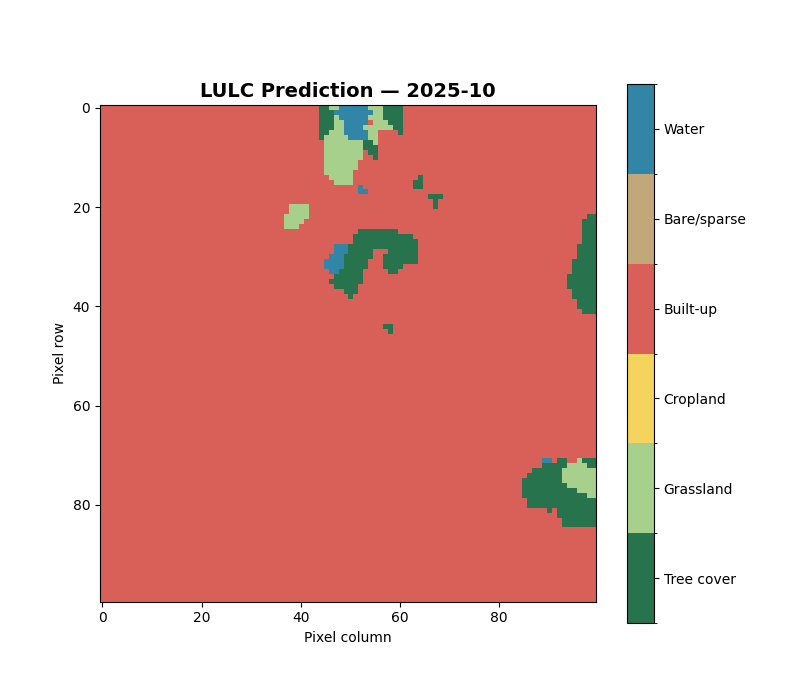

In [60]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import Image, display

# Consistent class colors
class_colors = [
    "#26734D",  # Tree cover
    "#A8D08D",  # Grassland
    "#F4D35E",  # Cropland
    "#D95F59",  # Built-up
    "#C2A878",  # Bare/sparse vegetation
    "#3185A6"   # Permanent water
]

cmap = ListedColormap(class_colors)

norm = BoundaryNorm(
    [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5],
    cmap.N
)

run_months = [
    item["label"] for item in run_schedule
]

animation_path = (
    project_root
    / "arbitrary_location_test"
    / "configurable_lulc_12_months.gif"
)

fig, ax = plt.subplots(figsize=(8, 7))

image_plot = ax.imshow(
    run_monthly_maps[run_months[0]],
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

title = ax.set_title(
    f"LULC Prediction — {run_months[0]}",
    fontsize=14,
    weight="bold"
)

ax.set_xlabel("Pixel column")
ax.set_ylabel("Pixel row")

colorbar = fig.colorbar(
    image_plot,
    ax=ax,
    ticks=[1, 2, 3, 4, 5, 6]
)

colorbar.ax.set_yticklabels([
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse",
    "Water"
])

def update(frame):
    month = run_months[frame]

    image_plot.set_data(run_monthly_maps[month])
    title.set_text(
        f"LULC Prediction — {month}"
    )

    return image_plot, title

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(run_months),
    interval=1000,
    blit=False,
    repeat=True
)

ani.save(
    animation_path,
    writer=animation.PillowWriter(fps=1)
)

plt.close(fig)

print("Animation saved:", animation_path)
print("Frames:", len(run_months))

display(Image(filename=str(animation_path)))

In [61]:
from pathlib import Path
import ast

src_dir = project_root / "src"

print("EXISTING SOURCE MODULES")
print("=" * 60)

for path in sorted(src_dir.glob("*.py")):

    print(f"\nFILE: {path.name}")

    source = path.read_text()
    tree = ast.parse(source)

    for node in tree.body:

        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            print(f"  Function: {node.name}")

        elif isinstance(node, ast.ClassDef):
            print(f"  Class: {node.name}")

print("\nPROJECT ENTRY POINTS")
print("=" * 60)

for filename in ["app.py", "requirements.txt", "README.md"]:
    path = project_root / filename
    print(f"{filename}: {'EXISTS' if path.exists() else 'NOT FOUND'}")

EXISTING SOURCE MODULES

FILE: __init__.py

FILE: analysis.py
  Function: calculate_transition_matrix
  Function: analyze_monthly_maps
  Function: calculate_interval_transitions

FILE: inference.py
  Function: predict_raster

FILE: location.py
  Function: create_location_window
  Function: extract_monthly_maps

FILE: model.py
  Class: DoubleConv
  Class: UNet
  Function: load_v5_model

PROJECT ENTRY POINTS
app.py: EXISTS
requirements.txt: NOT FOUND
README.md: NOT FOUND


In [62]:
import ast

# ==========================================
# INSPECT EXISTING APP
# ==========================================

app_path = project_root / "app.py"

print("EXISTING STREAMLIT APP")
print("=" * 70)

app_source = app_path.read_text()

print(app_source)

# ==========================================
# INSPECT MODULE FUNCTION SIGNATURES
# ==========================================

import inspect
from src import analysis, inference, location, model

modules = {
    "analysis": analysis,
    "inference": inference,
    "location": location,
    "model": model
}

print("\n\nMODULE FUNCTION SIGNATURES")
print("=" * 70)

for module_name, module in modules.items():

    print(f"\n[{module_name}]")

    for name, obj in inspect.getmembers(
        module,
        inspect.isfunction
    ):
        if obj.__module__ == module.__name__:
            print(f"{name}{inspect.signature(obj)}")

EXISTING STREAMLIT APP

import sys
from pathlib import Path

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import plotly.express as px

# --------------------------------------------------
# PROJECT PATHS AND IMPORTS
# --------------------------------------------------

PROJECT_DIR = Path(__file__).resolve().parent
sys.path.insert(0, str(PROJECT_DIR))

from src.location import (
    create_location_window,
    extract_monthly_maps,
    CLASS_NAMES
)

from src.analysis import analyze_monthly_maps

PREDICTION_DIR = PROJECT_DIR / "prototype_outputs"
OUTPUT_DIR = PREDICTION_DIR / "dashboard_results"

MONTHS = [
    "2025_10", "2025_11", "2025_12", "2026_01",
    "2026_02", "2026_03", "2026_04", "2026_05",
    "2026_06", "2026_07", "2026_08", "2026_09"
]

# --------------------------------------------------
# Shared LULC class colours
# Keep these colours consistent across all dashboard tabs.
# ---------

In [63]:
from pathlib import Path

src_dir = project_root / "src"

modules_to_inspect = [
    "location.py",
    "analysis.py",
    "inference.py"
]

for filename in modules_to_inspect:

    file_path = src_dir / filename

    print("\n" + "=" * 80)
    print(f"FILE: {filename}")
    print("=" * 80)

    print(file_path.read_text())


FILE: location.py
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

from pyproj import Transformer
from rasterio.transform import rowcol
from rasterio.windows import Window


CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}


def create_location_window(
    reference_path,
    latitude,
    longitude,
    area_size_metres=1000,
    pixel_size_metres=10,
):
    """
    Convert latitude/longitude into a centred raster window.

    Returns the selection window and spatial metadata.
    """

    if not -90 <= latitude <= 90:
        raise ValueError("Latitude must be between -90 and 90.")

    if not -180 <= longitude <= 180:
        raise ValueError("Longitude must be between -180 and 180.")

    if area_size_metres <= 0 or pixel_size_metres <= 0:
        raise ValueError("Area and pixel sizes must be positive.")

    if area_size_metres % pixel_size_

In [65]:
from src.location import create_utm_grid

test_grid_module = create_utm_grid(
    latitude=48.7758,
    longitude=9.1829,
    area_size_m=1000,
    pixel_size_m=10
)

print(test_grid_module)

ImportError: cannot import name 'create_utm_grid' from 'src.location' (/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/src/location.py)

In [66]:
from pathlib import Path
import importlib
import src.location as location_module

location_path = project_root / "src" / "location.py"

print("File exists:", location_path.exists())
print("\nLast 50 lines of location.py:")
print("\n".join(location_path.read_text().splitlines()[-50:]))

# Reload the module
importlib.reload(location_module)

print("\nFunction available:",
      hasattr(location_module, "create_utm_grid"))

File exists: True

Last 50 lines of location.py:
    )

    crs = CRS.from_epsg(epsg)

    transformer = Transformer.from_crs(
        "EPSG:4326",
        crs,
        always_xy=True
    )

    x, y = transformer.transform(longitude, latitude)

    half = area_size_m / 2

    left = x - half
    right = x + half
    bottom = y - half
    top = y + half

    width = area_size_m // pixel_size_m
    height = width

    transform = Affine(
        pixel_size_m,
        0,
        left,
        0,
        -pixel_size_m,
        top
    )

    return {
        "crs": crs.to_string(),
        "epsg": epsg,
        "projection": ee_projection_placeholder if False else None,
        "transform": [
            pixel_size_m, 0, left,
            0, -pixel_size_m, top
        ],
        "affine": transform,
        "bounds": (left, bottom, right, top),
        "width": width,
        "height": height,
        "center_x": x,
        "center_y": y,
        "latitude": latitude,
        "longitude":

In [67]:
from src.location import create_utm_grid

test_grid_module = create_utm_grid(
    latitude=48.7758,
    longitude=9.1829,
    area_size_m=1000,
    pixel_size_m=10
)

print("CRS:", test_grid_module["crs"])
print("EPSG:", test_grid_module["epsg"])
print("Dimensions:", test_grid_module["width"], "x", test_grid_module["height"])
print("Pixel size:", test_grid_module["pixel_size_m"], "m")
print("Bounds:", test_grid_module["bounds"])
print("Transform:", test_grid_module["transform"])

CRS: EPSG:32632
EPSG: 32632
Dimensions: 100 x 100
Pixel size: 10 m
Bounds: (512937.70616791205, 5402049.149969402, 513937.70616791205, 5403049.149969402)
Transform: [10, 0, 512937.70616791205, 0, -10, 5403049.149969402]


In [68]:
from pathlib import Path

analysis_path = Path("src/analysis.py")

print(analysis_path.read_text())

from pathlib import Path

import numpy as np
import pandas as pd


CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}

CLASS_IDS = list(CLASS_NAMES.keys())


def calculate_transition_matrix(previous_map, current_map):
    """Calculate a 6x6 class-to-class transition matrix."""

    if previous_map.shape != current_map.shape:
        raise ValueError("Input maps must have identical shapes.")

    matrix = np.zeros((6, 6), dtype=np.int64)

    for i, from_class in enumerate(CLASS_IDS):
        for j, to_class in enumerate(CLASS_IDS):
            matrix[i, j] = np.sum(
                (previous_map == from_class)
                & (current_map == to_class)
            )

    return matrix


def analyze_monthly_maps(
    monthly_maps,
    months,
    output_dir=None,
):
    """
    Calculate monthly percentages, temporal stability,
    switches, month-to-month changes and transition mat

In [69]:
from src.analysis import analyze_monthly_maps
import inspect

print(inspect.signature(analyze_monthly_maps))

(monthly_maps, months, output_dir=None)


In [71]:
import importlib
import src.analysis as analysis_module

importlib.reload(analysis_module)

import inspect
print(inspect.signature(analysis_module.analyze_monthly_maps))

(monthly_maps, months, output_dir=None, pixel_size_m=10)


In [72]:
import numpy as np
from src.analysis import analyze_monthly_maps

test_maps = {
    "2025-01": np.array([
        [1, 1],
        [2, 2],
    ]),
    "2025-02": np.array([
        [1, 1],
        [2, 3],
    ]),
}

result_10m = analyze_monthly_maps(
    test_maps, ["2025-01", "2025-02"], pixel_size_m=10
)

result_20m = analyze_monthly_maps(
    test_maps, ["2025-01", "2025-02"], pixel_size_m=20
)

print("10 m changed area (ha):",
      result_10m["monthly_changes"].iloc[0]["changed_area_hectares"])

print("20 m changed area (ha):",
      result_20m["monthly_changes"].iloc[0]["changed_area_hectares"])

10 m changed area (ha): 0.01
20 m changed area (ha): 0.04


In [75]:
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

ee_grid_test = gee_module.create_ee_grid(test_grid_module)

print("Projection:", ee_grid_test["projection"].getInfo())
print("Region:", ee_grid_test["region"].getInfo())

Projection: {'type': 'Projection', 'crs': 'EPSG:32632', 'transform': [10, 0, 512937.70616791205, 0, -10, 5403049.149969402]}
Region: {'geodesic': False, 'crs': {'type': 'name', 'properties': {'name': 'EPSG:32632'}}, 'type': 'Polygon', 'coordinates': [[[512937.70616791205, 5402049.149969402], [513937.70616791205, 5402049.149969402], [513937.70616791205, 5403049.149969402], [512937.70616791205, 5403049.149969402], [512937.70616791205, 5402049.149969402]]]}


In [82]:
import importlib
import src.gee as gee_module

# Reload the latest saved version
importlib.reload(gee_module)

# Verify the function is available
print("Function available:",
      hasattr(gee_module, "get_sentinel1_collection"))

# Test October 2025
test_collection = gee_module.get_sentinel1_collection(
    ee_grid_test["region"],
    "2025-10-01",
    "2025-11-01",
)

print("October 2025 scene count:",
      test_collection.size().getInfo())

Function available: True
October 2025 scene count: 5


In [81]:
from pathlib import Path

gee_path = Path("src/gee.py")

print("File exists:", gee_path.exists())
print("\n--- Current gee.py contents ---\n")
print(gee_path.read_text())

File exists: True

--- Current gee.py contents ---

import ee

def create_ee_grid(grid):
    """
    Convert a UTM grid dictionary into an Earth Engine
    projection and rectangular region.
    """

    # Projection with the exact pixel alignment
    projection = ee.Projection(
        grid["crs"],
        grid["transform"],
    )

    # Region uses the CRS only, without the affine transform
    left, bottom, right, top = grid["bounds"]

    region = ee.Geometry.Rectangle(
        [left, bottom, right, top],
        proj=grid["crs"],
        geodesic=False,
    )

    return {
        "projection": projection,
        "region": region,
    }

def get_sentinel1_collection(region, start_date, end_date):
    """
    Retrieve Sentinel-1 GRD scenes for a region and date range.

    Uses IW mode, descending pass, and VV/VH polarization.
    """

    collection = (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(region)
        .filterDate(start_date, end_date)
        

In [85]:
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

print("Function available:",
      hasattr(gee_module, "get_monthly_scene_counts"))

print("\nCurrent functions:")
print([
    name for name in dir(gee_module)
    if name.startswith("get_")
])

Function available: True

Current functions:
['get_monthly_scene_counts', 'get_sentinel1_collection']


In [86]:
from datetime import date
from dateutil.relativedelta import relativedelta
import pandas as pd

months_test = []
start = date(2025, 10, 1)

for i in range(12):
    month_start = start + relativedelta(months=i)
    month_end = month_start + relativedelta(months=1)

    months_test.append({
        "label": month_start.strftime("%Y-%m"),
        "start": month_start.isoformat(),
        "end": month_end.isoformat(),
    })

monthly_counts = gee_module.get_monthly_scene_counts(
    ee_grid_test["region"],
    months_test,
)

display(pd.DataFrame(monthly_counts))

,month,scene_count,available
0,2025-10,5,True
1,2025-11,4,True
2,2025-12,5,True
3,2026-01,5,True
4,2026-02,5,True
5,2026-03,5,True
6,2026-04,6,True
7,2026-05,6,True
8,2026-06,6,True
9,2026-07,5,True


In [92]:
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

orbit_results = gee_module.get_monthly_orbit_counts(
    ee_grid_test["region"],
    months_test,
)

for item in orbit_results:
    print(item["month"], item["orbit_counts"])

2025-10 {66: 5}
2025-11 {66: 4}
2025-12 {66: 5}
2026-01 {66: 5}
2026-02 {66: 5}
2026-03 {66: 5}
2026-04 {66: 6}
2026-05 {66: 6}
2026-06 {66: 6}
2026-07 {66: 5}
2026-08 {66: 6}
2026-09 {66: 5}


In [90]:
from pathlib import Path

gee_path = Path("src/gee.py")
source = gee_path.read_text()

old = "int(orbit): int(count)"
new = "int(float(orbit)): int(count)"

print("Old expression occurrences:", source.count(old))

assert source.count(old) == 1, "Expected exactly one occurrence. Check the file."

gee_path.write_text(source.replace(old, new))

print("Updated:", new)

Old expression occurrences: 1
Updated: int(float(orbit)): int(count)


In [91]:
for i, line in enumerate(gee_path.read_text().splitlines(), 1):
    if 95 <= i <= 104:
        print(f"{i}: {line}")

95:             "relativeOrbitNumber_start"
96:         ).getInfo()
97: 
98:         results.append({
99:             "month": month["label"],
100:             "orbit_counts": {
101:                 int(float(orbit)): int(count)
102:                 for orbit, count in orbit_counts.items()
103:             },
104:         })


In [93]:
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

orbit_selection = gee_module.select_consistent_orbit(
    orbit_results
)

print(orbit_selection)

{'selected_orbit': 66, 'consistent': True, 'common_orbits': [66], 'scene_counts': {66: 63}}


In [94]:
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

october_composite = gee_module.create_monthly_composite(
    region=ee_grid_test["region"],
    projection=ee_grid_test["projection"],
    month=months_test[0],
    relative_orbit=orbit_selection["selected_orbit"],
)

print("Bands:", october_composite.bandNames().getInfo())
print("Properties:", october_composite.toDictionary([
    "month",
    "relative_orbit",
    "scene_count",
]).getInfo())

Bands: ['VV', 'VH']
Properties: {'month': '2025-10', 'relative_orbit': 66, 'scene_count': 5}


In [95]:
print("Projection:")
print(october_composite.select("VV").projection().getInfo())

print("\nPixel statistics:")

stats = october_composite.reduceRegion(
    reducer=ee.Reducer.minMax().combine(
        reducer2=ee.Reducer.mean(),
        sharedInputs=True,
    ),
    geometry=ee_grid_test["region"],
    crs=test_grid_module["crs"],
    crsTransform=test_grid_module["transform"],
    maxPixels=100000,
).getInfo()

print(stats)

Projection:
{'type': 'Projection', 'crs': 'EPSG:32632', 'transform': [10, 0, 512937.70616791205, 0, -10, 5403049.149969402]}

Pixel statistics:
{'VH_max': 11.26623797985433, 'VH_mean': -11.136580036066947, 'VH_min': -26.180992862987523, 'VV_max': 17.99661725658947, 'VV_mean': -4.501709379403183, 'VV_min': -18.780926090945314}


In [96]:
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

from pathlib import Path

october_path = gee_module.download_monthly_composite(
    composite=october_composite,
    region=ee_grid_test["region"],
    grid=test_grid_module,
    output_path=Path("arbitrary_location_test/monthly_inputs/2025-10.tif"),
)

print("Downloaded:", october_path)
print("File exists:", october_path.exists())
print("File size:", october_path.stat().st_size, "bytes")

Downloaded: arbitrary_location_test/monthly_inputs/2025-10.tif
File exists: True
File size: 156274 bytes


In [97]:
import rasterio
import numpy as np

with rasterio.open(october_path) as src:
    print("CRS:", src.crs)
    print("Dimensions:", src.width, "x", src.height)
    print("Band count:", src.count)
    print("Band descriptions:", src.descriptions)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Data types:", src.dtypes)
    print("NoData:", src.nodata)

    for i, name in enumerate(["VV", "VH"], start=1):
        band = src.read(i)
        valid = band[np.isfinite(band)]

        print(f"\n{name} statistics:")
        print("Min:", valid.min())
        print("Max:", valid.max())
        print("Mean:", valid.mean())
        print("Valid pixels:", valid.size)

CRS: EPSG:32632
Dimensions: 100 x 100
Band count: 2
Band descriptions: (None, None)
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=512937.70616791205, bottom=5402049.149969402, right=513937.70616791205, top=5403049.149969402)
Data types: ('float64', 'float64')
NoData: None

VV statistics:
Min: -18.780926090945314
Max: 17.99661725658947
Mean: -4.50170937940318
Valid pixels: 10000

VH statistics:
Min: -26.180992862987523
Max: 11.26623797985433
Mean: -11.13658003606695
Valid pixels: 10000


In [98]:
import importlib
from pathlib import Path
import src.gee as gee_module

importlib.reload(gee_module)

input_dir = Path("arbitrary_location_test/monthly_inputs")
input_dir.mkdir(parents=True, exist_ok=True)

downloaded_paths = [october_path]

for month in months_test[1:]:
    print(f"Processing {month['label']}...")

    composite = gee_module.create_monthly_composite(
        region=ee_grid_test["region"],
        projection=ee_grid_test["projection"],
        month=month,
        relative_orbit=orbit_selection["selected_orbit"],
    )

    output_path = gee_module.download_monthly_composite(
        composite=composite,
        region=ee_grid_test["region"],
        grid=test_grid_module,
        output_path=input_dir / f"{month['label']}.tif",
    )

    downloaded_paths.append(output_path)

    print(f"  Downloaded: {output_path.stat().st_size:,} bytes")

print("\nTotal downloaded:", len(downloaded_paths))

Processing 2025-11...
  Downloaded: 156,278 bytes
Processing 2025-12...
  Downloaded: 156,281 bytes
Processing 2026-01...
  Downloaded: 156,260 bytes
Processing 2026-02...
  Downloaded: 156,250 bytes
Processing 2026-03...
  Downloaded: 156,292 bytes
Processing 2026-04...
  Downloaded: 156,208 bytes
Processing 2026-05...
  Downloaded: 156,242 bytes
Processing 2026-06...
  Downloaded: 156,289 bytes
Processing 2026-07...
  Downloaded: 156,360 bytes
Processing 2026-08...
  Downloaded: 156,324 bytes
Processing 2026-09...
  Downloaded: 156,337 bytes

Total downloaded: 12


In [99]:
import rasterio
import numpy as np
import pandas as pd

validation_rows = []

for path in sorted(downloaded_paths):
    with rasterio.open(path) as src:
        vv = src.read(1)
        vh = src.read(2)

        validation_rows.append({
            "month": path.stem,
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "crs": str(src.crs),
            "resolution": src.res,
            "vv_valid": int(np.isfinite(vv).sum()),
            "vh_valid": int(np.isfinite(vh).sum()),
            "vv_mean": float(np.nanmean(vv)),
            "vh_mean": float(np.nanmean(vh)),
            "valid": (
                src.width == 100
                and src.height == 100
                and src.count == 2
                and str(src.crs) == "EPSG:32632"
                and np.isfinite(vv).all()
                and np.isfinite(vh).all()
            ),
        })

validation_df = pd.DataFrame(validation_rows)

display(validation_df)

print("\nAll 12 files valid:", validation_df["valid"].all())

,month,width,height,bands,crs,resolution,vv_valid,vh_valid,vv_mean,vh_mean,valid
0,2025-10,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.501709,-11.136580,True
1,2025-11,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.496860,-10.897672,True
2,2025-12,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.530284,-10.891298,True
3,2026-01,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.557956,-10.883485,True
4,2026-02,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.570381,-10.850386,True
5,2026-03,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.514526,-10.748651,True
6,2026-04,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.568535,-10.831544,True
7,2026-05,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.522220,-10.842941,True
8,2026-06,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.422759,-10.711687,True
9,2026-07,100,100,2,EPSG:32632,"(10.0, 10.0)",10000,10000,-4.532762,-10.710583,True



All 12 files valid: True


In [100]:
from pathlib import Path
import numpy as np
import rasterio

from src.inference import predict_raster

checkpoint_path = Path("outputs/best_unet_v5.pt")

assert checkpoint_path.exists(), (
    f"Model checkpoint not found: {checkpoint_path.resolve()}"
)

prediction_dir = Path("arbitrary_location_test/monthly_predictions")
prediction_dir.mkdir(parents=True, exist_ok=True)

october_prediction_path = prediction_dir / "2025-10_prediction.tif"

predict_raster(
    input_path=october_path,
    output_path=october_prediction_path,
    checkpoint_path=checkpoint_path,
    batch_size=16,
    patch_size=128,
)

print("Prediction exists:", october_prediction_path.exists())

Prediction exists: True


In [101]:
with rasterio.open(october_prediction_path) as src:
    prediction = src.read(1)

    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Unique predicted classes:", np.unique(prediction))
    print("Class pixel counts:", {
        int(c): int(n)
        for c, n in zip(*np.unique(prediction, return_counts=True))
    })

Dimensions: 100 x 100
CRS: EPSG:32632
Unique predicted classes: [1 2 4 6]
Class pixel counts: {1: 402, 2: 228, 4: 9353, 6: 17}


In [102]:
from pathlib import Path

from src.inference import predict_raster

prediction_dir = Path("arbitrary_location_test/monthly_predictions")
prediction_dir.mkdir(parents=True, exist_ok=True)

prediction_paths = [october_prediction_path]

for input_path in sorted(downloaded_paths)[1:]:
    month = input_path.stem
    output_path = prediction_dir / f"{month}_prediction.tif"

    print(f"Predicting {month}...")

    predict_raster(
        input_path=input_path,
        output_path=output_path,
        checkpoint_path=checkpoint_path,
        batch_size=16,
        patch_size=128,
    )

    prediction_paths.append(output_path)
    print(f"  Saved: {output_path}")

print("\nTotal predictions:", len(prediction_paths))

Predicting 2025-11...
  Saved: arbitrary_location_test/monthly_predictions/2025-11_prediction.tif
Predicting 2025-12...
  Saved: arbitrary_location_test/monthly_predictions/2025-12_prediction.tif
Predicting 2026-01...
  Saved: arbitrary_location_test/monthly_predictions/2026-01_prediction.tif
Predicting 2026-02...
  Saved: arbitrary_location_test/monthly_predictions/2026-02_prediction.tif
Predicting 2026-03...
  Saved: arbitrary_location_test/monthly_predictions/2026-03_prediction.tif
Predicting 2026-04...
  Saved: arbitrary_location_test/monthly_predictions/2026-04_prediction.tif
Predicting 2026-05...
  Saved: arbitrary_location_test/monthly_predictions/2026-05_prediction.tif
Predicting 2026-06...
  Saved: arbitrary_location_test/monthly_predictions/2026-06_prediction.tif
Predicting 2026-07...
  Saved: arbitrary_location_test/monthly_predictions/2026-07_prediction.tif
Predicting 2026-08...
  Saved: arbitrary_location_test/monthly_predictions/2026-08_prediction.tif
Predicting 2026-09..

In [103]:
import numpy as np
import rasterio
import pandas as pd

validation_results = []

for path in sorted(prediction_paths):
    with rasterio.open(path) as src:
        prediction = src.read(1)
        unique_classes = np.unique(prediction)

        validation_results.append({
            "Month": path.stem.replace("_prediction", ""),
            "Dimensions": f"{src.width} x {src.height}",
            "CRS": str(src.crs),
            "Valid dimensions": src.width == 100 and src.height == 100,
            "Valid CRS": str(src.crs) == "EPSG:32632",
            "Class IDs valid": set(unique_classes).issubset(
                {0, 1, 2, 3, 4, 5, 6}
            ),
            "Unique classes": unique_classes.tolist(),
            "Pixel count": int(prediction.size),
        })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nAll dimensions valid:",
      validation_df["Valid dimensions"].all())

print("All CRS valid:",
      validation_df["Valid CRS"].all())

print("All class IDs valid:",
      validation_df["Class IDs valid"].all())

,Month,Dimensions,CRS,Valid dimensions,Valid CRS,Class IDs valid,Unique classes,Pixel count
0,2025-10,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
1,2025-11,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
2,2025-12,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
3,2026-01,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
4,2026-02,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
5,2026-03,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
6,2026-04,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
7,2026-05,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
8,2026-06,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000
9,2026-07,100 x 100,EPSG:32632,True,True,True,"[1, 2, 4, 6]",10000



All dimensions valid: True
All CRS valid: True
All class IDs valid: True


In [104]:
import inspect
from src import analysis

print(inspect.signature(analysis.analyze_monthly_maps))
print(inspect.getsource(analysis.analyze_monthly_maps))

(monthly_maps, months, output_dir=None, pixel_size_m=10)
def analyze_monthly_maps(
    monthly_maps,
    months,
    output_dir=None,
    pixel_size_m=10,
):

    if pixel_size_m <= 0:
        raise ValueError("pixel_size_m must be greater than zero.")

    pixel_area_ha = (pixel_size_m ** 2) / 10000


    """
    Calculate monthly percentages, temporal stability,
    switches, month-to-month changes and transition matrices.

    monthly_maps: dictionary mapping month strings to 2D arrays.
    months: ordered list of month strings.
    """

    if len(months) < 2:
        raise ValueError("At least two months are required.")

    if len(set(months)) != len(months):
        raise ValueError("Month names must be unique.")

    missing = [m for m in months if m not in monthly_maps]

    if missing:
        raise ValueError(f"Missing monthly maps: {missing}")

    reference_shape = monthly_maps[months[0]].shape

    if len(reference_shape) != 2:
        raise ValueError("Monthly maps must 

In [105]:
import numpy as np
import rasterio
from pathlib import Path
from src import analysis

# 1. Load the 12 prediction rasters
monthly_maps = {}

for path in sorted(prediction_paths):
    month = path.stem.replace("_prediction", "")

    with rasterio.open(path) as src:
        monthly_maps[month] = src.read(1)

months = sorted(monthly_maps.keys())

# 2. Run analysis
analysis_output_dir = Path(
    "arbitrary_location_test/analysis"
)

results = analysis.analyze_monthly_maps(
    monthly_maps=monthly_maps,
    months=months,
    output_dir=analysis_output_dir,
    pixel_size_m=10,
)

# 3. Display monthly class coverage
print("MONTHLY LAND-COVER COVERAGE (%)")
display(
    results["monthly_percentages"].round(2)
)

# 4. Display month-to-month changes
print("\nMONTH-TO-MONTH CHANGES")
display(results["monthly_changes"])

# 5. First-to-last change summary
print("\nOCTOBER 2025 → SEPTEMBER 2026")
print("Total pixels:", results["total_pixels"])
print("Changed pixels:", results["changed_pixels"])
print("Unchanged pixels:", results["unchanged_pixels"])
print("Changed area (%):", round(results["changed_percentage"], 2))

# 6. Temporal stability
print("\nTEMPORAL STABILITY")
print(results["stability"])

# 7. First-to-last transition matrix
print("\nFIRST-TO-LAST TRANSITION MATRIX")
display(results["first_last_transition_matrix"])

MONTHLY LAND-COVER COVERAGE (%)


,month,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
0,2025-10,4.02,2.28,0.0,93.53,0.0,0.17
1,2025-11,4.29,2.77,0.0,92.76,0.0,0.18
2,2025-12,4.96,2.37,0.0,92.40,0.0,0.27
3,2026-01,4.46,2.19,0.0,93.05,0.0,0.30
4,2026-02,5.16,2.12,0.0,92.58,0.0,0.14
5,2026-03,5.45,2.14,0.0,92.38,0.0,0.03
6,2026-04,6.54,3.19,0.0,89.42,0.0,0.85
7,2026-05,6.10,1.62,0.0,91.19,0.0,1.09
8,2026-06,6.20,3.09,0.0,89.94,0.0,0.77
9,2026-07,4.56,1.69,0.0,93.59,0.0,0.16



MONTH-TO-MONTH CHANGES


,period,changed_pixels,changed_area_hectares,area_hectares
0,2025-10 → 2025-11,339,3.39,3.39
1,2025-11 → 2025-12,331,3.31,3.31
2,2025-12 → 2026-01,315,3.15,3.15
3,2026-01 → 2026-02,346,3.46,3.46
4,2026-02 → 2026-03,368,3.68,3.68
5,2026-03 → 2026-04,650,6.50,6.50
6,2026-04 → 2026-05,513,5.13,5.13
7,2026-05 → 2026-06,582,5.82,5.82
8,2026-06 → 2026-07,628,6.28,6.28
9,2026-07 → 2026-08,465,4.65,4.65



OCTOBER 2025 → SEPTEMBER 2026
Total pixels: 10000
Changed pixels: 488
Unchanged pixels: 9512
Changed area (%): 4.88

TEMPORAL STABILITY
{'stable_all_months': 8610, 'two_distinct_classes': 1219, 'three_or_more_distinct_classes': 171}

FIRST-TO-LAST TRANSITION MATRIX


,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
From / To,,,,,,
Tree cover,209,42,0,151,0,0
Grassland,13,129,0,26,0,60
Cropland,0,0,0,0,0,0
Built-up,93,80,0,9174,0,6
Bare/sparse vegetation,0,0,0,0,0,0
Permanent water,0,0,0,17,0,0


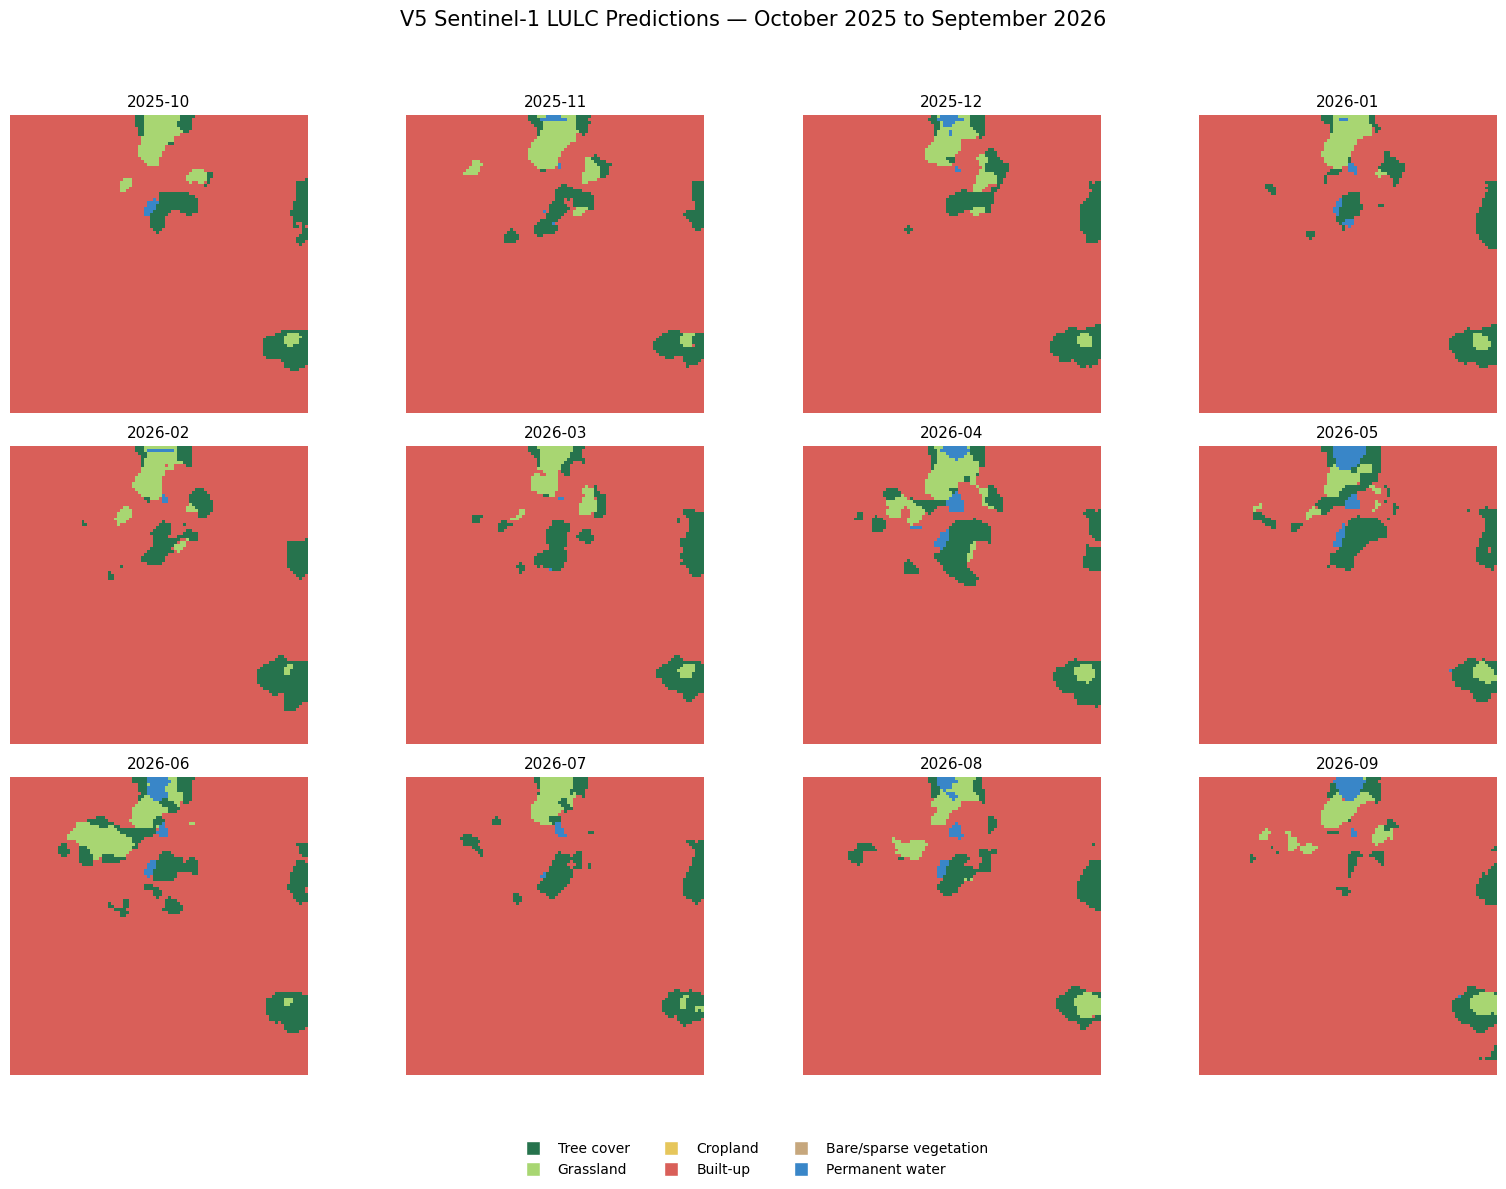

In [106]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

from pathlib import Path
import rasterio

# Consistent colors for all months
class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}

class_colors = {
    1: "#26734D",
    2: "#A8D672",
    3: "#E6C65B",
    4: "#D95F59",
    5: "#C6A77D",
    6: "#3986C8",
}

cmap = mcolors.ListedColormap(
    [class_colors[i] for i in range(1, 7)]
)

norm = mcolors.BoundaryNorm(
    np.arange(0.5, 7.5, 1),
    cmap.N
)

fig, axes = plt.subplots(
    3, 4,
    figsize=(16, 12)
)

for ax, path in zip(axes.flat, sorted(prediction_paths)):

    with rasterio.open(path) as src:
        prediction = src.read(1)

    ax.imshow(
        prediction,
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    month = path.stem.replace("_prediction", "")
    ax.set_title(month, fontsize=11)
    ax.axis("off")

legend_items = [
    plt.Line2D(
        [0], [0],
        marker="s",
        color="w",
        markerfacecolor=class_colors[class_id],
        markersize=10,
        label=class_names[class_id]
    )
    for class_id in class_names
]

fig.legend(
    handles=legend_items,
    loc="lower center",
    ncol=3,
    frameon=False
)

plt.suptitle(
    "V5 Sentinel-1 LULC Predictions — October 2025 to September 2026",
    fontsize=15
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

TEMPORAL INSTABILITY
0 switches: 8610 pixels (86.10%)
1 switches: 71 pixels (0.71%)
2 switches: 425 pixels (4.25%)
3 switches: 186 pixels (1.86%)
4 switches: 354 pixels (3.54%)
5 switches: 161 pixels (1.61%)
6 switches: 97 pixels (0.97%)
7 switches: 62 pixels (0.62%)
8 switches: 26 pixels (0.26%)
9 switches: 8 pixels (0.08%)


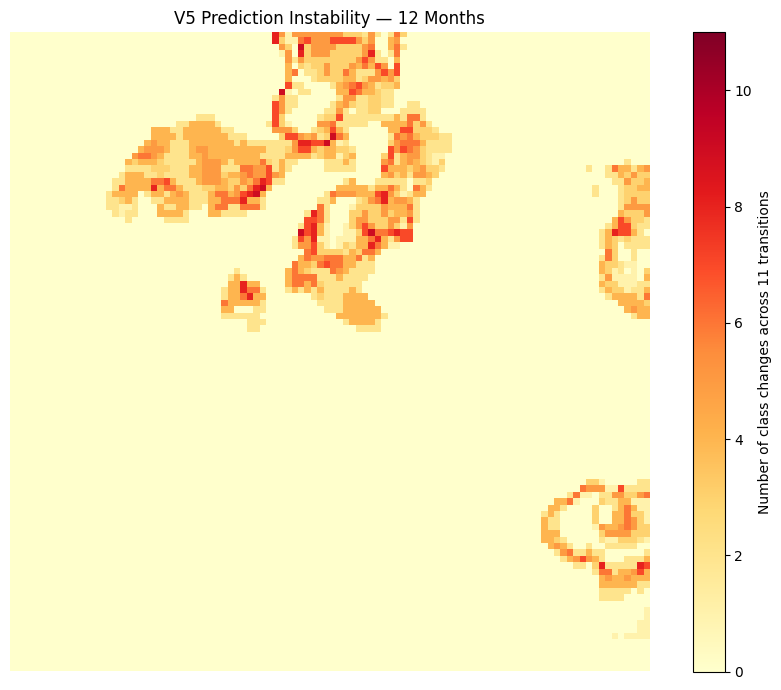

In [107]:
import numpy as np
import matplotlib.pyplot as plt

# Stack monthly predictions
prediction_stack = np.stack(
    [monthly_maps[m] for m in months],
    axis=0
)

# Count class changes between consecutive months
switch_map = np.sum(
    prediction_stack[1:] != prediction_stack[:-1],
    axis=0
)

# Count pixels by number of switches
unique_switches, switch_counts = np.unique(
    switch_map,
    return_counts=True
)

print("TEMPORAL INSTABILITY")
for switches, count in zip(unique_switches, switch_counts):
    print(
        f"{switches} switches: {count} pixels "
        f"({count / switch_map.size * 100:.2f}%)"
    )

# Plot spatial distribution
plt.figure(figsize=(9, 7))

plt.imshow(
    switch_map,
    cmap="YlOrRd",
    interpolation="nearest",
    vmin=0,
    vmax=11
)

plt.colorbar(
    label="Number of class changes across 11 transitions"
)

plt.title("V5 Prediction Instability — 12 Months")
plt.axis("off")
plt.tight_layout()
plt.show()

In [108]:
import numpy as np
import pandas as pd

# Identify stable and unstable pixels
stable_mask = switch_map == 0
unstable_mask = switch_map > 0

# Class IDs and names
class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}

# Stable pixels have the same class in every month.
stable_classes = prediction_stack[0][stable_mask]

stable_rows = []

for class_id, class_name in class_names.items():
    count = int(np.sum(stable_classes == class_id))

    stable_rows.append({
        "Class": class_name,
        "Stable pixels": count,
        "Share of all stable pixels (%)": (
            count / stable_mask.sum() * 100
        ),
    })

stable_df = pd.DataFrame(stable_rows)

print("STABLE PIXELS BY CLASS")
display(stable_df.round(2))

# For unstable pixels, calculate the most frequently predicted class.
unstable_stack = prediction_stack[:, unstable_mask]

unstable_rows = []

for class_id, class_name in class_names.items():
    count = int(np.sum(unstable_stack == class_id))

    unstable_rows.append({
        "Class": class_name,
        "Monthly predictions": count,
        "Share of unstable-pixel predictions (%)": (
            count / unstable_stack.size * 100
        ),
    })

unstable_df = pd.DataFrame(unstable_rows)

print("CLASS FREQUENCY WITHIN UNSTABLE PIXELS")
display(unstable_df.round(2))

STABLE PIXELS BY CLASS


,Class,Stable pixels,Share of all stable pixels (%)
0,Tree cover,93,1.08
1,Grassland,46,0.53
2,Cropland,0,0.00
3,Built-up,8471,98.39
4,Bare/sparse vegetation,0,0.00
5,Permanent water,0,0.00


CLASS FREQUENCY WITHIN UNSTABLE PIXELS


,Class,Monthly predictions,Share of unstable-pixel predictions (%)
0,Tree cover,4799,28.77
1,Grassland,2293,13.75
2,Cropland,0,0.00
3,Built-up,9061,54.32
4,Bare/sparse vegetation,0,0.00
5,Permanent water,527,3.16


In [110]:
import inspect
from src import gee

print(inspect.signature(gee.create_ee_grid))
print(inspect.getsource(gee.create_ee_grid))

(grid)
def create_ee_grid(grid):
    """
    Convert a UTM grid dictionary into an Earth Engine
    projection and rectangular region.
    """

    # Projection with the exact pixel alignment
    projection = ee.Projection(
        grid["crs"],
        grid["transform"],
    )

    # Region uses the CRS only, without the affine transform
    left, bottom, right, top = grid["bounds"]

    region = ee.Geometry.Rectangle(
        [left, bottom, right, top],
        proj=grid["crs"],
        geodesic=False,
    )

    return {
        "projection": projection,
        "region": region,
    }



In [111]:
from pathlib import Path
import ee
import rasterio
import numpy as np

from src import gee

# 1. Recreate the exact Earth Engine grid
ee_grid = gee.create_ee_grid(test_grid_module)

# 2. Load ESA WorldCover 2021 v200
worldcover_image = (
    ee.ImageCollection("ESA/WorldCover/v200")
    .first()
    .select("Map")
    .reproject(crs=ee_grid["projection"])
    .clip(ee_grid["region"])
)

# 3. Download onto the same 10 m grid
worldcover_path = Path(
    "arbitrary_location_test/reference/worldcover_2021.tif"
)

gee.download_monthly_composite(
    composite=worldcover_image,
    region=ee_grid["region"],
    grid=test_grid_module,
    output_path=worldcover_path,
)

print("Downloaded:", worldcover_path)
print("File exists:", worldcover_path.exists())

# 4. Verify spatial alignment
with rasterio.open(worldcover_path) as src:
    worldcover_raw = src.read(1)

    print("\nWorldCover dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Transform:", src.transform)
    print("Unique original class codes:", np.unique(worldcover_raw))
    print("Class pixel counts:", {
        int(c): int(n)
        for c, n in zip(*np.unique(
            worldcover_raw, return_counts=True
        ))
    })

# 5. Compare with October prediction grid
with rasterio.open(october_prediction_path) as pred_src:
    print("\nPrediction dimensions:", pred_src.width, "x", pred_src.height)
    print("Same CRS:", pred_src.crs == rasterio.open(worldcover_path).crs)
    print("Same transform:", pred_src.transform == rasterio.open(worldcover_path).transform)

Downloaded: arbitrary_location_test/reference/worldcover_2021.tif
File exists: True

WorldCover dimensions: 100 x 100
CRS: EPSG:32632
Transform: | 10.00, 0.00, 512937.71|
| 0.00,-10.00, 5403049.15|
| 0.00, 0.00, 1.00|
Unique original class codes: [10 30 40 50 60 80]
Class pixel counts: {10: 1401, 30: 300, 40: 5, 50: 8203, 60: 3, 80: 88}

Prediction dimensions: 100 x 100
Same CRS: True
Same transform: True


In [112]:
import numpy as np
import pandas as pd
import rasterio

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    cohen_kappa_score,
)

# Load October prediction
with rasterio.open(october_prediction_path) as src:
    prediction = src.read(1)

# Map WorldCover codes to V5 class IDs
worldcover_mapping = {
    10: 1,  # Tree cover
    30: 2,  # Grassland
    40: 3,  # Cropland
    50: 4,  # Built-up
    60: 5,  # Bare/sparse vegetation
    80: 6,  # Permanent water
}

reference = np.zeros(worldcover_raw.shape, dtype=np.uint8)

for original_id, model_id in worldcover_mapping.items():
    reference[worldcover_raw == original_id] = model_id

# Compare all six mapped classes
class_ids = [1, 2, 3, 4, 5, 6]

cm = confusion_matrix(
    reference.ravel(),
    prediction.ravel(),
    labels=class_ids,
)

class_names = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water",
]

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names,
)

print("CONFUSION MATRIX")
print("Rows = WorldCover reference; columns = V5 prediction")
display(cm_df)

print("\nOVERALL AGREEMENT")
print("Overall accuracy:", round(
    accuracy_score(reference.ravel(), prediction.ravel()), 4
))
print("Cohen's kappa:", round(
    cohen_kappa_score(reference.ravel(), prediction.ravel()), 4
))

print("\nCLASSIFICATION REPORT")
print(classification_report(
    reference.ravel(),
    prediction.ravel(),
    labels=class_ids,
    target_names=class_names,
    zero_division=0,
))

CONFUSION MATRIX
Rows = WorldCover reference; columns = V5 prediction


,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
Tree cover,329,30,0,1037,0,5
Grassland,16,71,0,201,0,12
Cropland,0,0,0,5,0,0
Built-up,56,40,0,8107,0,0
Bare/sparse vegetation,0,3,0,0,0,0
Permanent water,1,84,0,3,0,0



OVERALL AGREEMENT
Overall accuracy: 0.8507
Cohen's kappa: 0.3407

CLASSIFICATION REPORT
                        precision    recall  f1-score   support

            Tree cover       0.82      0.23      0.36      1401
             Grassland       0.31      0.24      0.27       300
              Cropland       0.00      0.00      0.00         5
              Built-up       0.87      0.99      0.92      8203
Bare/sparse vegetation       0.00      0.00      0.00         3
       Permanent water       0.00      0.00      0.00        88

              accuracy                           0.85     10000
             macro avg       0.33      0.24      0.26     10000
          weighted avg       0.84      0.85      0.82     10000



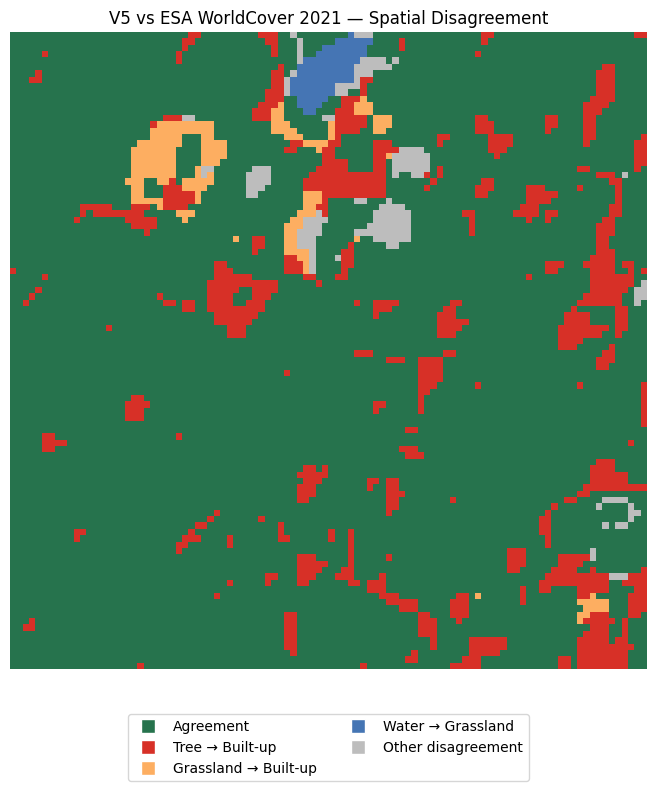

In [113]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Create disagreement categories
# 0 = Agreement
# 1 = Tree cover -> Built-up
# 2 = Grassland -> Built-up
# 3 = Water -> Grassland
# 4 = Other disagreement

disagreement = np.zeros(reference.shape, dtype=np.uint8)

mismatch = reference != prediction
disagreement[mismatch] = 4

disagreement[
    (reference == 1) & (prediction == 4)
] = 1

disagreement[
    (reference == 2) & (prediction == 4)
] = 2

disagreement[
    (reference == 6) & (prediction == 2)
] = 3

colors = [
    "#26734D",
    "#D73027",
    "#FDAE61",
    "#4575B4",
    "#BDBDBD",
]

labels = [
    "Agreement",
    "Tree → Built-up",
    "Grassland → Built-up",
    "Water → Grassland",
    "Other disagreement",
]

cmap = ListedColormap(colors)

plt.figure(figsize=(10, 8))

plt.imshow(
    disagreement,
    cmap=cmap,
    interpolation="nearest",
    vmin=0,
    vmax=4,
)

plt.title(
    "V5 vs ESA WorldCover 2021 — Spatial Disagreement"
)

legend_items = [
    plt.Line2D(
        [0], [0],
        marker="s",
        color="w",
        markerfacecolor=colors[i],
        markersize=10,
        label=labels[i],
    )
    for i in range(len(labels))
]

plt.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.06),
    ncol=2,
)

plt.axis("off")
plt.tight_layout()
plt.show()

In [114]:
import inspect
from src import inference

print(inspect.getsource(inference.predict_raster))

def predict_raster(
    input_path,
    output_path,
    checkpoint_path,
    batch_size=16,
    patch_size=128,
    device=None,
):
    """
    Generate a Sentinel-1 LULC prediction GeoTIFF.

    Preprocessing and tiling follow the original V5 prototype:
    - VV/VH checkpoint-based median-IQR normalization
    - 128x128 non-overlapping tiles
    - Reflect padding at bottom and right edges
    - Batched U-Net inference
    - Argmax predictions converted to class IDs 1-6
    """

    input_path = Path(input_path)
    output_path = Path(output_path)
    checkpoint_path = Path(checkpoint_path)

    if not input_path.is_file():
        raise FileNotFoundError(input_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)

    if batch_size < 1 or patch_size < 1:
        raise ValueError("batch_size and patch_size must be positive.")

    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Load the trained model and checkpoint metadata.
    mod

In [115]:
import numpy as np
import rasterio

from src.model import load_v5_model

checkpoint_path = "outputs/best_unet_v5.pt"

model, checkpoint = load_v5_model(checkpoint_path)

print("CHECKPOINT NORMALIZATION")
print("Medians:", checkpoint["class_medians"])
print("IQR:", checkpoint["class_iqr"])

print("\nEXPECTED V5 TRAINING NORMALIZATION")
print("VV median: -9.042964")
print("VH median: -15.390633")
print("VV IQR: 3.967108")
print("VH IQR: 4.469688")

print("\nNEW LOCATION — OCTOBER 2025")

with rasterio.open(october_path) as src:
    radar = src.read().astype(np.float32)

    for i, band_name in enumerate(["VV", "VH"]):
        values = radar[i]

        print(f"\n{band_name}")
        print("Min:", np.min(values))
        print("Max:", np.max(values))
        print("Mean:", np.mean(values))
        print("Median:", np.median(values))
        print("IQR:", np.percentile(values, 75) -
              np.percentile(values, 25))

        normalized = (
            values - checkpoint["class_medians"][i]
        ) / checkpoint["class_iqr"][i]

        print("Normalized mean:", np.mean(normalized))
        print("Normalized std:", np.std(normalized))
        print("Normalized min:", np.min(normalized))
        print("Normalized max:", np.max(normalized))

CHECKPOINT NORMALIZATION
Medians: [-9.042964, -15.390633]
IQR: [3.967108, 4.4696884]

EXPECTED V5 TRAINING NORMALIZATION
VV median: -9.042964
VH median: -15.390633
VV IQR: 3.967108
VH IQR: 4.469688

NEW LOCATION — OCTOBER 2025

VV
Min: -18.780926
Max: 17.996616
Mean: -4.5017095
Median: -5.1131253
IQR: 7.1097126
Normalized mean: 1.1447266
Normalized std: 1.3218646
Normalized min: -2.4546752
Normalized max: 6.815943

VH
Min: -26.180992
Max: 11.266238
Mean: -11.1365795
Median: -11.506954
IQR: 7.50229
Normalized mean: 0.95175594
Normalized std: 1.2166134
Normalized min: -2.414119
Normalized max: 5.9639215


In [116]:
from pathlib import Path

root = Path(".")

print("POTENTIAL TRAINING DATA FILES\n")

extensions = {".npz", ".npy", ".tif", ".tiff"}

for path in sorted(root.rglob("*")):
    if (
        path.is_file()
        and path.suffix.lower() in extensions
        and any(
            word in str(path).lower()
            for word in ["train", "dataset", "patch", "sentinel", "sample"]
        )
    ):
        print(path, f"({path.stat().st_size / 1024:.1f} KB)")

POTENTIAL TRAINING DATA FILES

arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2025-10.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2025-11.tif (152.6 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2025-12.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-01.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-02.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-03.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-04.tif (152.6 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-05.tif (152.6 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-06.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentinel1_vv_vh_2026-07.tif (152.7 KB)
arbitrary_location_test/configurable_monthly_inputs/sentine

In [117]:
import zipfile
import numpy as np
from pathlib import Path

train_path = Path("patches_v5/train_v5.npz")

print("Training dataset:", train_path)
print("File size (GB):", round(train_path.stat().st_size / 1e9, 3))

# Inspect NPZ metadata without loading the full arrays
with zipfile.ZipFile(train_path, "r") as archive:

    print("\nDATASET ARRAYS")

    for name in archive.namelist():

        if not name.endswith(".npy"):
            continue

        with archive.open(name) as file:
            version = np.lib.format.read_magic(file)

            if version == (1, 0):
                shape, fortran_order, dtype = (
                    np.lib.format.read_array_header_1_0(file)
                )
            else:
                shape, fortran_order, dtype = (
                    np.lib.format.read_array_header_2_0(file)
                )

        print({
            "array": name,
            "shape": shape,
            "dtype": str(dtype),
            "fortran_order": fortran_order,
        })

Training dataset: patches_v5/train_v5.npz
File size (GB): 1.221

DATASET ARRAYS
{'array': 'X.npy', 'shape': (8280, 2, 128, 128), 'dtype': 'float32', 'fortran_order': False}
{'array': 'y.npy', 'shape': (8280, 128, 128), 'dtype': 'uint8', 'fortran_order': False}
{'array': 'metadata.npy', 'shape': (8280,), 'dtype': "[('month', '<U7'), ('block', '<U4'), ('row', '<i4'), ('col', '<i4')]", 'fortran_order': False}
{'array': 'class_medians.npy', 'shape': (2,), 'dtype': 'float32', 'fortran_order': False}
{'array': 'class_iqr.npy', 'shape': (2,), 'dtype': 'float32', 'fortran_order': False}
{'array': 'months.npy', 'shape': (12,), 'dtype': '<U7', 'fortran_order': False}


In [118]:
outer_path = Path(
    "patches_v5_outer_ring/outer_ring_X_2025_10.npy"
)

outer = np.load(outer_path, mmap_mode="r")

print("\nOUTER-RING TRAINING INPUT")
print("Shape:", outer.shape)
print("Dtype:", outer.dtype)
print("Min:", float(np.min(outer)))
print("Max:", float(np.max(outer)))
print("Mean:", float(np.mean(outer)))
print("Median:", float(np.median(outer)))


OUTER-RING TRAINING INPUT
Shape: (600, 2, 128, 128)
Dtype: float32
Min: -5.254179954528809
Max: 9.663639068603516
Mean: -0.12779192626476288
Median: -0.17496415972709656


In [119]:
import numpy as np
import rasterio
import pandas as pd

# 1. Load arbitrary-location October data and normalize with V5 stats
with rasterio.open(october_path) as src:
    new_radar = src.read().astype(np.float32)

medians = np.asarray(checkpoint["class_medians"], dtype=np.float32)
iqr = np.asarray(checkpoint["class_iqr"], dtype=np.float32)

new_normalized = (
    new_radar - medians[:, None, None]
) / iqr[:, None, None]

# 2. Load October outer-ring training patches
outer_path = "patches_v5_outer_ring/outer_ring_X_2025_10.npy"
outer = np.load(outer_path, mmap_mode="r")

# 3. Compare distributions per band
percentiles = [0, 1, 5, 25, 50, 75, 95, 99, 100]

rows = []

for band_index, band_name in enumerate(["VV", "VH"]):

    new_values = new_normalized[band_index].ravel()
    outer_values = np.asarray(outer[:, band_index]).ravel()

    for dataset_name, values in [
        ("New location — October 2025", new_values),
        ("V5 outer-ring training — October 2025", outer_values),
    ]:
        values = values[np.isfinite(values)]

        row = {
            "Band": band_name,
            "Dataset": dataset_name,
            "Mean": np.mean(values),
            "Std": np.std(values),
        }

        for p in percentiles:
            row[f"P{p}"] = np.percentile(values, p)

        rows.append(row)

comparison_df = pd.DataFrame(rows)

display(comparison_df.round(3))

,Band,Dataset,Mean,Std,P0,P1,P5,P25,P50,P75,P95,P99,P100
0,VV,New location — October 2025,1.145,1.322,-2.455,-1.352,-0.710,0.178,0.991,1.970,3.491,4.892,6.816
1,VV,V5 outer-ring training — October 2025,-0.061,0.789,-4.881,-1.624,-1.148,-0.513,-0.121,0.274,1.251,2.706,9.664
2,VH,New location — October 2025,0.952,1.217,-2.414,-1.341,-0.837,0.041,0.869,1.720,3.061,4.312,5.964
3,VH,V5 outer-ring training — October 2025,-0.195,0.645,-5.254,-1.558,-1.133,-0.591,-0.226,0.138,0.852,1.826,8.258


In [120]:
from pathlib import Path

search_terms = [
    "create_monthly_composite",
    "outer_ring_X_2025_10",
    "train_v5",
    "class_medians",
    "class_iqr",
]

for term in search_terms:
    print(f"\n{'='*20} {term} {'='*20}")

    for path in Path(".").rglob("*.ipynb"):
        if any(part.startswith(".") for part in path.parts):
            continue

        try:
            import json

            notebook = json.loads(path.read_text())

            for i, cell in enumerate(notebook.get("cells", [])):
                source = "".join(cell.get("source", []))

                if term.lower() in source.lower():
                    print(f"Notebook: {path}, cell: {i}")
                    print(source[:2500])

        except Exception:
            pass


==================== create_monthly_composite ====================
Notebook: 11_arbitrary_location_workflow..ipynb, cell: 70
import importlib
import src.gee as gee_module

importlib.reload(gee_module)

october_composite = gee_module.create_monthly_composite(
    region=ee_grid_test["region"],
    projection=ee_grid_test["projection"],
    month=months_test[0],
    relative_orbit=orbit_selection["selected_orbit"],
)

print("Bands:", october_composite.bandNames().getInfo())
print("Properties:", october_composite.toDictionary([
    "month",
    "relative_orbit",
    "scene_count",
]).getInfo())
Notebook: 11_arbitrary_location_workflow..ipynb, cell: 74
import importlib
from pathlib import Path
import src.gee as gee_module

importlib.reload(gee_module)

input_dir = Path("arbitrary_location_test/monthly_inputs")
input_dir.mkdir(parents=True, exist_ok=True)

downloaded_paths = [october_path]

for month in months_test[1:]:
    print(f"Processing {month['label']}...")

    composite = gee_modu